# Intro

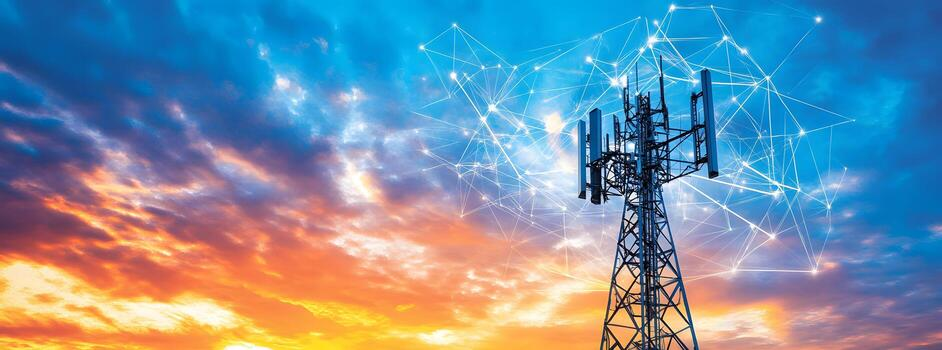
Dataset is a fictional Telecommunications company from [Maven Analytics](https://mavenanalytics.io/data-playground/telecom-customer-churn) that provides phone and internet services to 7,043 customers in California for fiscal quarter end 2022, from March 2022 to June 2022. The dataset has 38 columns with one of them the target variable.

The goal is:
1. To identify characteristics that most differentiate churned customers from retained ones.
2. To build a prioritized list of at-risk, high-value customers that for the team to contact proactively. 
3. Provide recommendations on how best to do so based on data analytics.

Variables:
1. First 9 are basic customer information
    - 'Customer ID', 'Gender', 'Age', 'Married', 'Number of Dependents',
       'City', 'Zip Code', 'Latitude', 'Longitude'
2. Next 3 are other key customer information
    - 'Number of Referrals', 'Tenure in Months', 'Offer'
3. Next 3 are Phone services
    - 'Phone Service', 'Avg Monthly Long Distance Charges', 'Multiple Lines'
4. Next 3 are Internet services
    - 'Internet Service', 'Internet Type', 'Avg Monthly GB Download'
5. Next 4 are additional value-added services
    - 'Online Security', 'Online Backup', 'Device Protection Plan',
       'Premium Tech Support'
6. Next 3 are streaming services
    - 'Streaming TV', 'Streaming Movies', 'Streaming Music'
7. Next 5 are contract details
    - 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charge'
8. Next 5 are total revenue computed from 4 variables
    - 'Total Charges', 'Total Refunds',
       'Total Extra Data Charges', 'Total Long Distance Charges',
       'Total Revenue'
9. Next 2 are churn category and reason
    - 'Churn Category', 'Churn Reason'
10. Last is target variable, 'Customer Status'.
    - <b>Churned</b> means a customer left during the observed period of 12 months, and by the end of Q2 2022, the person no longer becomes an active customer.
    - <b>Stayed</b> means a customer is already an existing customer before the observed period, and remained active through the end of the period.
    - <b>Joined</b> means a customer that became a new customer during the observed period, and remained active through the end of the period.

For churn analytics, I will be removing Joined Customers for more accurate representation (this step is done after data cleaning).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

In [2]:
telcom = pd.read_csv('./datasets/telecom_customer_churn.csv')
telcom_dict = pd.read_csv('./datasets/telecom_data_dictionary.csv', encoding='iso-8859-1')

df = telcom.copy()
df.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,9,NaN,Yes,42.39,No,Yes,Cable,16.0,No,Yes,No,Yes,Yes,No,No,Yes,One Year,Yes,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,9,NaN,Yes,10.69,Yes,Yes,Cable,10.0,No,No,No,No,No,Yes,Yes,No,Month-to-Month,No,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,4,Offer E,Yes,33.65,No,Yes,Fiber Optic,30.0,No,No,Yes,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,13,Offer D,Yes,27.82,No,Yes,Fiber Optic,4.0,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,3,NaN,Yes,7.38,No,Yes,Fiber Optic,11.0,No,No,No,Yes,Yes,No,No,Yes,Month-to-Month,Yes,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   str    
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   str    
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   str    
 12  Pho

---
<a id="section-one"></a>
# EDA

<a id="section-two"></a>
## 1. Initial Setup: assessing dataset, identifying categorical & numerical columns

In [4]:
def dataset_check(df):
    print('-----------------Info-----------------')
    print(f'Shape: {df.shape}')
    print(f'Size: {df.size}')
    print(f'Observations: {len(df)}')
    print(f'Dimension: {df.ndim}\n')

    print('-----------------Datatype-----------------')
    print(f'{df.dtypes}\n')

    print('-----------------Missing Values-----------------')
    print(f'Number of columns with missing values: {(df.isna().sum() >0).sum()}\n')
    print(f'{df.isna().sum().sort_values(ascending=False)}\n')

    print('-----------------Duplicates-----------------')
    print(f'{df.duplicated().sum()}\n')

    print('-----------------Unique Values-----------------')
    print(f'{df.nunique()}\n')

    print('-----------------Describe-----------------')
    print(f'{df.describe()}\n')

In [5]:
dataset_check(df)

-----------------Info-----------------
Shape: (7043, 38)
Size: 267634
Observations: 7043
Dimension: 2

-----------------Datatype-----------------
Customer ID                              str
Gender                                   str
Age                                    int64
Married                                  str
Number of Dependents                   int64
City                                     str
Zip Code                               int64
Latitude                             float64
Longitude                            float64
Number of Referrals                    int64
Tenure in Months                       int64
Offer                                    str
Phone Service                            str
Avg Monthly Long Distance Charges    float64
Multiple Lines                           str
Internet Service                         str
Internet Type                            str
Avg Monthly GB Download              float64
Online Security                          str

In [6]:
num_cols = []
for i in df.columns:
    if df[i].dtype != 'str':
        num_cols.append(i)

modified_num_cols = [i for i in num_cols if i not in ['Zip Code', 'Latitude', 'Longitude']]
'''
    modified_num_cols is list that excludes locational variables, as it is not the focus of this project
'''

print('-----------------Num_cols-----------------')
print(f'Length: {len(num_cols)}')
print(f'{num_cols}\n')

print('-----------------Modified Num_cols-----------------')
print(f'Length: {len(modified_num_cols)}')
print(f'{modified_num_cols}\n')

cat_cols = [x for x in df.columns if x not in num_cols]
modified_cat_cols = [x for x in cat_cols if x not in ['Customer ID', 'City']]
'''
    modified_cat_cols excludes some variables:
        1. Customer ID is excluded because its not meaningful in analysis.
        2. City is excluded because it contains too many unique values (1106)
'''

print('-----------------Cat_cols-----------------')
print(f'Length: {len(cat_cols)}')
print(f'{cat_cols}\n')

print('-----------------Modified Cat_cols-----------------')
print(f'Length: {len(modified_cat_cols)}')
print(f'{modified_cat_cols}\n')

-----------------Num_cols-----------------
Length: 15
['Age', 'Number of Dependents', 'Zip Code', 'Latitude', 'Longitude', 'Number of Referrals', 'Tenure in Months', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']

-----------------Modified Num_cols-----------------
Length: 12
['Age', 'Number of Dependents', 'Number of Referrals', 'Tenure in Months', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']

-----------------Cat_cols-----------------
Length: 23
['Customer ID', 'Gender', 'Married', 'City', 'Offer', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streami

#### Overview

Overall, the dataset has 7043 customers and 37 features, and 1 target variable called Customer Status in either 'Churned', 'Stayed' or 'Joined'.

Datatypes for each column is right/ requires no correction for now.
Of the 15 numerical columns, 12 will be used for analysis.
Of the 23 categorical columns, 21 will be used for analysis.
Of the 38 columns, 15 have NULL values. 

There are no dupliates in this dataset. 


## 2. Handling Missing Data

Among the 15 variables with missing data, I suspect that they can be grouped and explained simply as such:

1. Group 1: Churn Reason and Churn Category
    - Missing values in these columns refer to customers that stayed or joined by the end of the period. They do not have a churn reason or churn category.
    - <u>verdict: replace NULL values with 'Not Applicable'.</u>
    
2. Group 2: Offer
    - Missing values in Offer refer to customers that did not accept an offer
    - <u>verdict: replace NULL values with 'None'.</u>
3. Group 3: 10 Internet ervice Variables
    - Missing values in these columns refer to customers that did not subscribe to any internet service
    - <u>verdict: replace NULL values with 'No', 'None' or 0.0, depending on the datatype.</u>
4. Group 4: Phone Service Varibles
    - Missing values in these columns refer to customers that did not subscribe to any phone service
    - <u>verdict: replace NULL with 'No' and 0.0</u>

In [7]:
#Checking if NULL values are as I suspect they are
#group 1
grp1_null_list = ['Churn Reason', 'Churn Category']
count1 = len(df[df[grp1_null_list].isna().all(axis=1)])
unchurned_customers = len(df[df['Customer Status']!='Churned'])
print('------------Group 1------------')
print(f'Number of non-churned customers is {unchurned_customers}')
print(f'Numbers equal? {count1==unchurned_customers}\n')


#group 3
grp3_null_list = ['Online Backup' , 'Online Security',
            'Streaming Movies', 'Streaming TV', 'Unlimited Data',
            'Streaming Music', 'Device Protection Plan',
            'Premium Tech Support']
count3 = len(df[df[grp3_null_list].isna().all(axis=1)])
no_is_customers = len(df[df['Internet Service']=='No'])
print('------------Group 3------------')
print(f'Number of customers not subscribed to internet service is {no_is_customers}')
print(f'Numbers equal? {count3==no_is_customers}\n')


#group 4
grp4_null_list = ['Avg Monthly Long Distance Charges' , 'Multiple Lines']
count4 = len(df[df[grp4_null_list].isna().all(axis=1)])
no_phone_service_customers = len(df[df['Phone Service']=='No'])
print('------------Group 4------------')
print(f'Number of customers not subscribed to home phone service is {no_phone_service_customers}')
print(f'Numbers equal? {count4==no_phone_service_customers}\n')


------------Group 1------------
Number of non-churned customers is 5174
Numbers equal? True

------------Group 3------------
Number of customers not subscribed to internet service is 1526
Numbers equal? True

------------Group 4------------
Number of customers not subscribed to home phone service is 682
Numbers equal? True



In [8]:
def handle_null():
    '''
    handles NULL values as specified eariler.
    '''

    grp1_null_list = ['Churn Reason', 'Churn Category']
    df.loc[df['Customer Status']!='Churned', grp1_null_list] = 'Not Applicable'

    grp2_null_list = ['Offer']
    df['Offer'] = df['Offer'].fillna('None')

    grp3_null_list_a = ['Online Backup' , 'Online Security',
                'Streaming Movies', 'Streaming TV', 'Unlimited Data',
                'Streaming Music', 'Device Protection Plan',
                'Premium Tech Support']
    grp3_null_list_b = ['Avg Monthly GB Download', 'Internet Type']
    df.loc[df['Internet Service']=='No', grp3_null_list_a] = 'No'
    df.loc[df['Internet Service']=='No', grp3_null_list_b] = [0.0, 'None']
    '''
        'Avg Monthly GB Download' is in float 0.0
        'Internet Type' is in 'None'
        The rest is in 'No'
    '''            
    grp4_null_list = ['Avg Monthly Long Distance Charges' , 'Multiple Lines']
    df.loc[df['Phone Service']=='No', grp4_null_list] = [0.0, 'No']
    '''
        'Avg Monthly Long Distance Charges' is in float 0.0
        'Multiple Lines' is in 'No'
    '''
    print(df.isna().sum().sort_values(ascending=False))

handle_null()

Customer ID                          0
Gender                               0
Age                                  0
Married                              0
Number of Dependents                 0
City                                 0
Zip Code                             0
Latitude                             0
Longitude                            0
Number of Referrals                  0
Tenure in Months                     0
Offer                                0
Phone Service                        0
Avg Monthly Long Distance Charges    0
Multiple Lines                       0
Internet Service                     0
Internet Type                        0
Avg Monthly GB Download              0
Online Security                      0
Online Backup                        0
Device Protection Plan               0
Premium Tech Support                 0
Streaming TV                         0
Streaming Movies                     0
Streaming Music                      0
Unlimited Data           

Now, the dataset no longer as any missing values. I will double check if Total Revenue is computed correctly. According to telcom_dict:

`Total Revenue = Total Charge - Total Refunds + Total Extra Data Charges + Total Long Distance Charges`

The code below will verify that formula.

In [9]:
df['validation_total_revenue'] = (df['Total Charges'] - df['Total Refunds'] + df['Total Extra Data Charges'] + df['Total Long Distance Charges']).round(2)
check = df['Total Revenue'].equals(df['validation_total_revenue'])
print(f'Is Total Revenue calculated correctly? {check}')

df = df.drop(columns='validation_total_revenue')

Is Total Revenue calculated correctly? True


## 3. Numerical Variables: outliers and skewness

### Part 1: Handling outliers

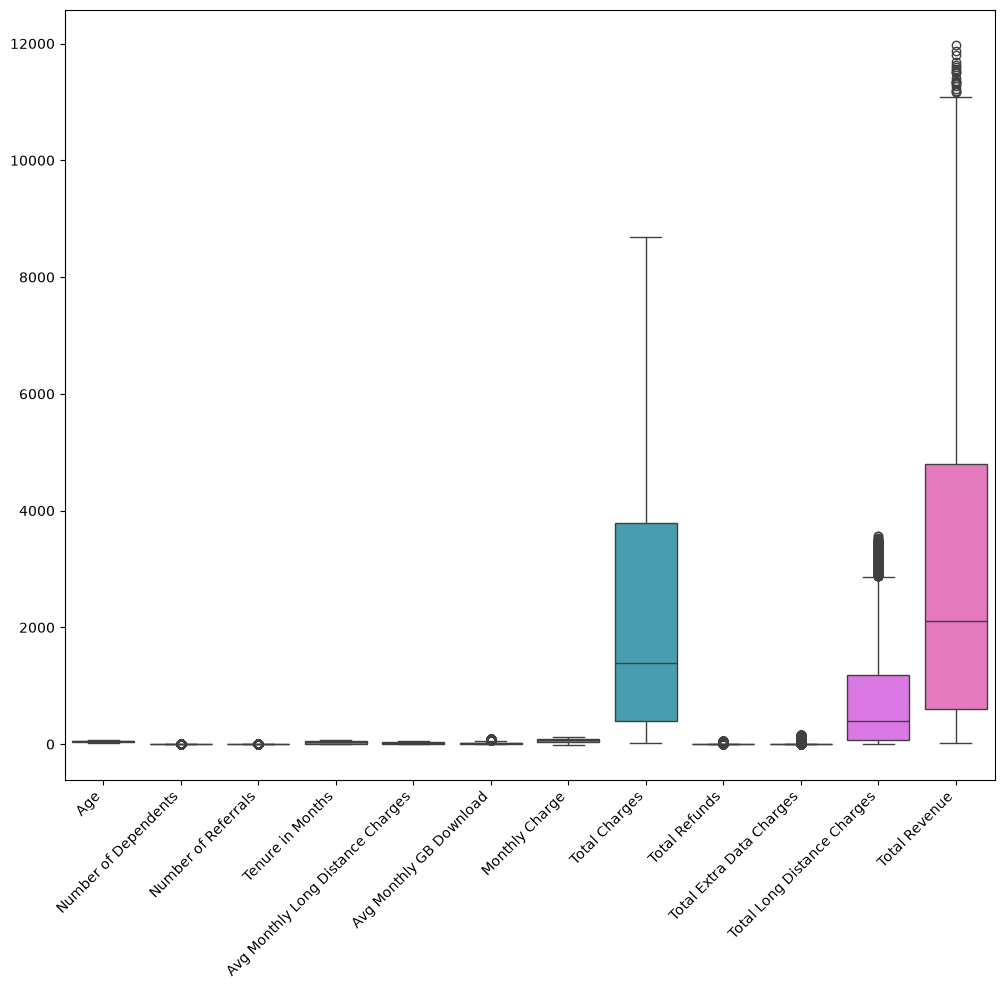

Number of outliers per column:
Age                                     0
Number of Dependents                 1627
Number of Referrals                   676
Tenure in Months                        0
Avg Monthly Long Distance Charges       0
Avg Monthly GB Download               362
Monthly Charge                          0
Total Charges                           0
Total Refunds                         525
Total Extra Data Charges              728
Total Long Distance Charges           196
Total Revenue                          21
dtype: int64

There are 7 variables with outliers:
['Number of Dependents', 'Number of Referrals', 'Avg Monthly GB Download', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']


In [10]:
plt.figure(figsize=(12,10))
df_plot = df[modified_num_cols]
sns.boxplot(data=df_plot)
plt.xticks(rotation=45, ha='right')
plt.savefig('images/outlier_boxplots.png', bbox_inches='tight',dpi=300)
plt.show()

Q1 = df_plot.quantile(0.25)
Q3 = df_plot.quantile(0.75)
IQR = Q3 - Q1

outliers_iqr = ((df_plot < (Q1 - 1.5 * IQR)) | (df_plot > (Q3 + 1.5 * IQR)))
print(f'Number of outliers per column:')
print(f'{outliers_iqr.sum()}\n')

df_temp = outliers_iqr.sum().reset_index()
num_cols_outliers = df_temp[df_temp[0]>0]['index'].to_list()
print(f'There are {(outliers_iqr.sum() >0).sum()} variables with outliers:')
print(num_cols_outliers)

Overall, there are a number of outliers in some variables. The code below puts each chart into subplots to further assess, since the graph above makes it difficult to see. 

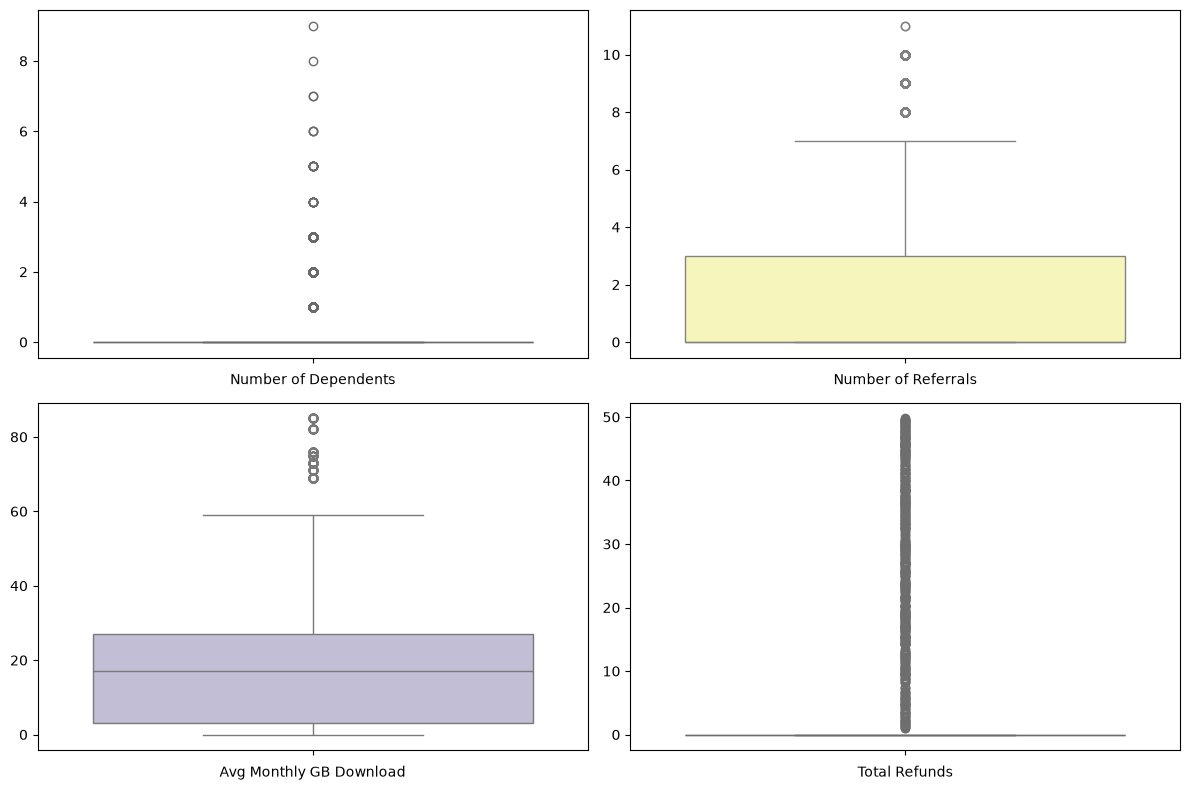

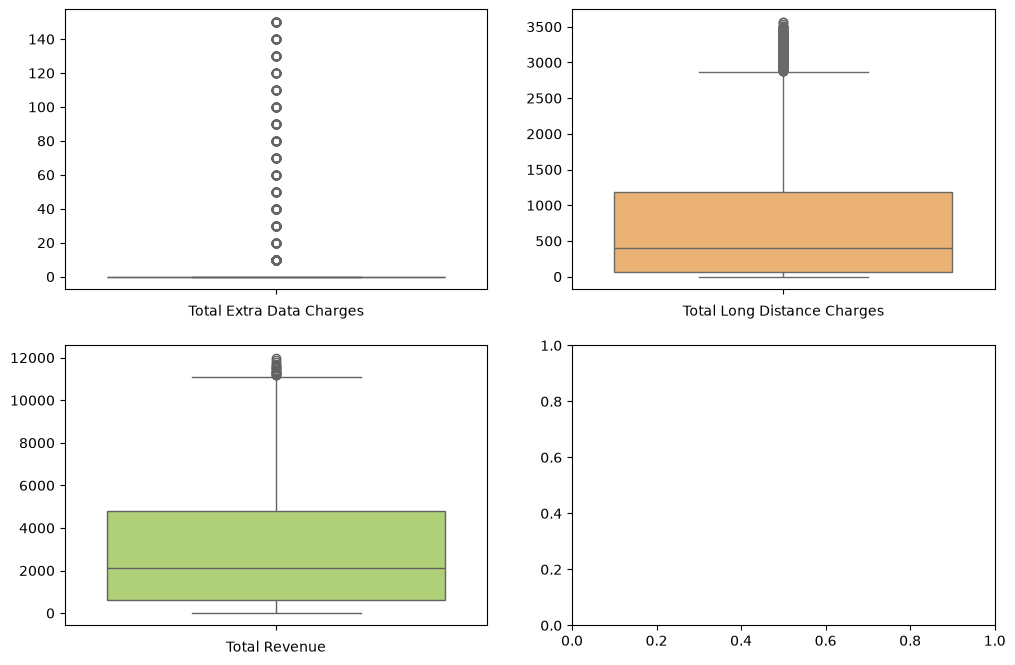

In [11]:
colors = sns.color_palette('Set3', len(num_cols_outliers))

fig, axes = plt.subplots(2,2, figsize=(12,8))
i,j =0, 0
count = 0

for col in num_cols_outliers:
    sns.boxplot(data=df[col], color=colors[count], ax=axes[i,j])
    axes[i,j].set_xlabel(col)
    axes[i,j].set_ylabel('')

    count +=1
    j +=1
    if j==2:
        i +=1
        j = 0
    if i==2:
        plt.tight_layout()
        plt.show()
        if count == len(num_cols_outliers):
            break
        fig, axes = plt.subplots(2,2, figsize=(12,8))
        i,j = 0,0

#### Overview

Overall, some of the more notable variables with outliers are as follows:


1. Number of Dependents: Most customers have 0 dependents (75th percentile is 0). Outliers are anywhere from 1 to 9.
2. Number of referrals: Most customers refer 0 people (75th percentile is 3), outliers reffering 8 to 11 people.
3. Total Extra Data Charges: Most customers do not incur extra charges (75th percentile is 0), those that do are outliers.
3. Total Refunds: Most do not seek a refund (75th percentile is 0), and those that do are outliers.
4. Total Revenue: A very small amount of customers (9 of them) bring in much more total revenue to the compay than the rest

It is accepted that all these outliers are <b>non-erroneous, and are considered rare but valid cases</b>. Hence, I decided to leave them as they are.

### Part 2: Handling skewness

According to [(Rani, 2025)](https://medium.com/@richa.insights/how-to-choose-the-right-number-of-bins-for-a-histogram-with-python-examples-c56c557d5ff8), I used two methods to calculate the optimal bin number:

1. If the variable has outliers or is not symmetric, then I used <b>Freedman-Diaconis Rule.</b>
2. If the variable is normally distributed, then I used <b>Scott's Rule.</b>


Additionally, I referenced this [(Vaddi, 2026)](https://machinelearningplus.com/statistics/skewness-and-kurtosis/#RulesofThumbforSkewness:) to gauge the skewness of each variable.

1. If skewness is less than -1 or greater than 1, the distribution is highly skewed.
2. If skewness is between -1 and -0.5 or between 0.5 and 1, the distribution is moderately skewed.
3. If skewness is between -0.5 and 0.5, the distribution is approximately symmetric.

C:\Users\user\AppData\Local\Temp\ipykernel_11356\2674463231.py:28: RuntimeWarning: divide by zero encountered in divide
  bin_num = int(np.ceil((col_max - col_min)/bin_width))


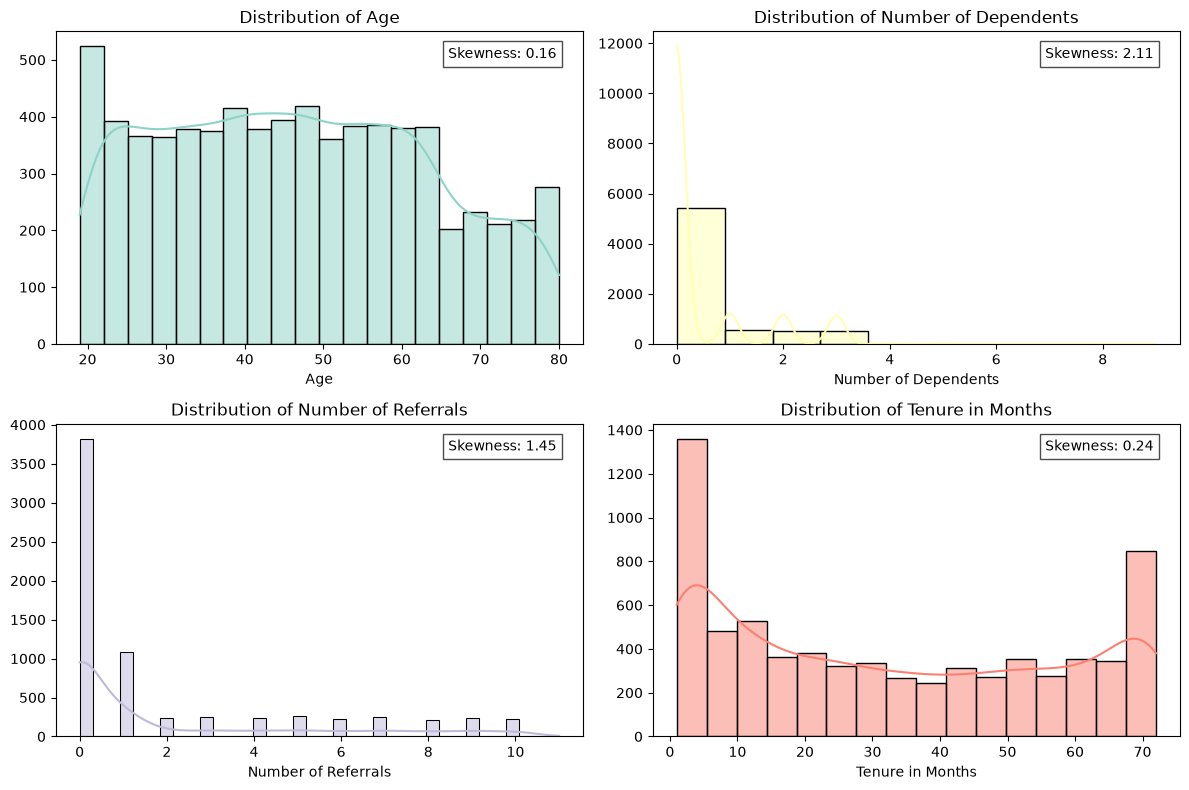

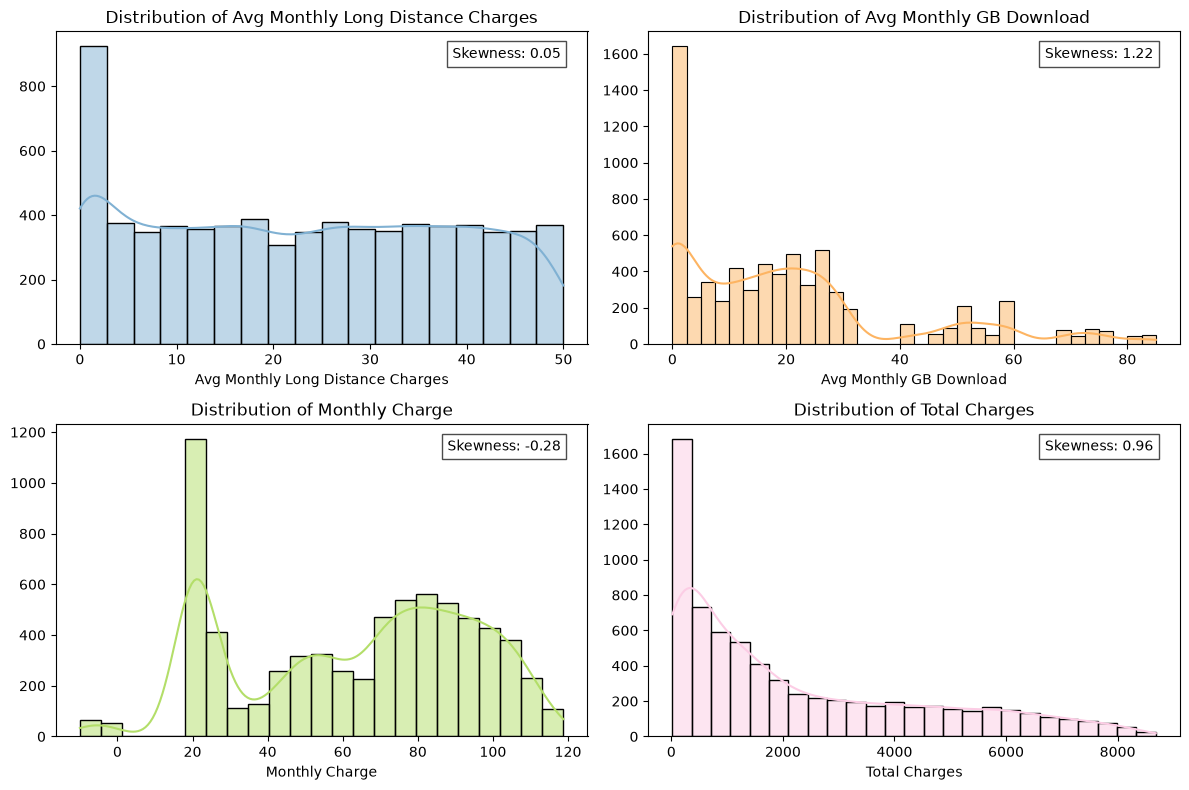

C:\Users\user\AppData\Local\Temp\ipykernel_11356\2674463231.py:28: RuntimeWarning: divide by zero encountered in scalar divide
  bin_num = int(np.ceil((col_max - col_min)/bin_width))
C:\Users\user\AppData\Local\Temp\ipykernel_11356\2674463231.py:28: RuntimeWarning: divide by zero encountered in divide
  bin_num = int(np.ceil((col_max - col_min)/bin_width))


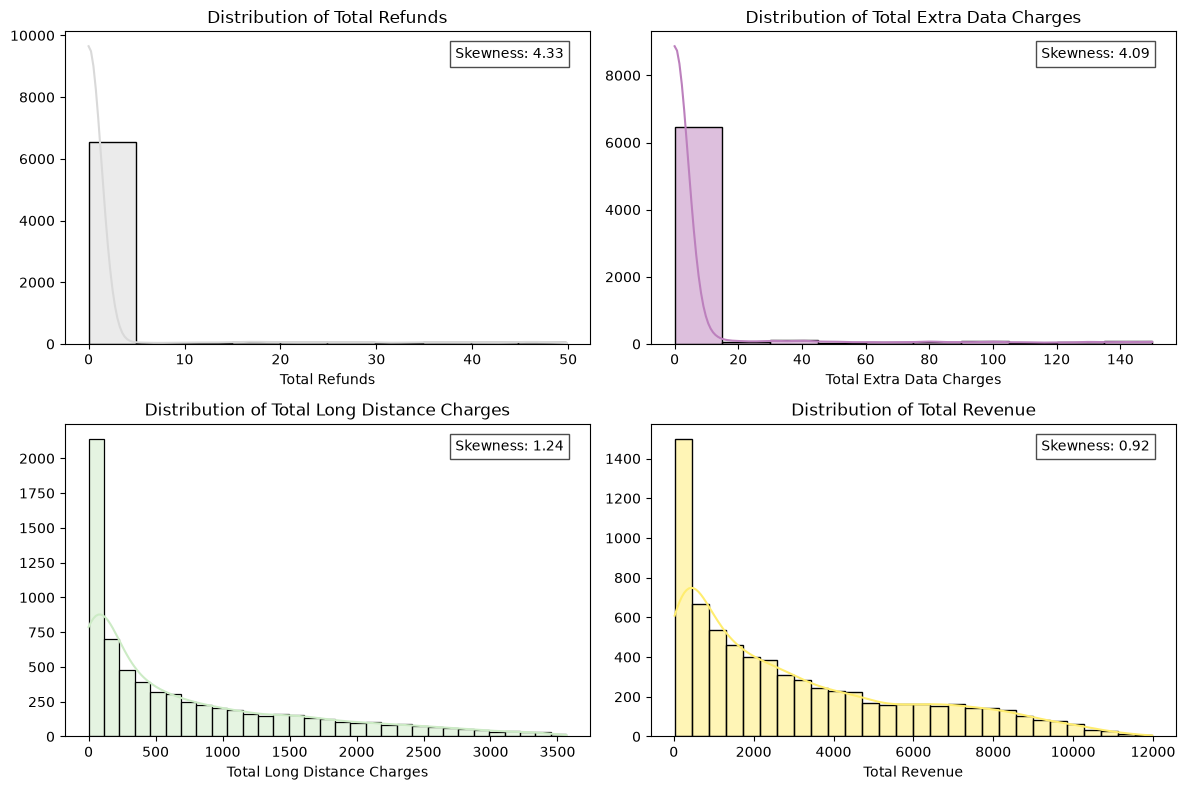

Variables with default 10 bin number due to 0 IQR are:
['Number of Dependents', 'Total Refunds', 'Total Extra Data Charges']

-----------Skewness-----------
Age                                  0.162186
Number of Dependents                 2.109932
Number of Referrals                  1.446060
Tenure in Months                     0.240543
Avg Monthly Long Distance Charges    0.049176
Avg Monthly GB Download              1.216584
Monthly Charge                      -0.275394
Total Charges                        0.963791
Total Refunds                        4.328517
Total Extra Data Charges             4.091209
Total Long Distance Charges          1.238282
Total Revenue                        0.919410
dtype: float64

-------Approximately Symmetric Variables-------
Age
Tenure in Months
Avg Monthly Long Distance Charges
Monthly Charge

-------Moderately Skewed variables-------
Total Charges
Total Revenue

-------Highly Skewed variables-------
Number of Dependents
Number of Referrals
Avg Mo

In [12]:
colors = sns.color_palette('Set3', len(modified_num_cols))

fig, axes = plt.subplots(2,2, figsize=(12,8))
i,j = 0,0
count = 0
iqr_0_cols = []

for col in modified_num_cols:   
    n= len(df[col])
    col_max = df[col].max()
    col_min = df[col].min()
    sk = df[col].skew()
    if abs(sk) <0.5:
        '''
        if roughly symmetric, then use Scott's rule, else use Freedman-Diaconis rule.
        '''
        std = np.std(df[col])
        bin_width = 3.5*std/(n**(1/3))
        bin_num = int(np.ceil((col_max - col_min)/bin_width))
    else:
        col_Q1, col_Q3 = df[col].quantile([0.25, 0.75])
        col_IQR = col_Q3 - col_Q1
        bin_width = 2*col_IQR/ (n**(1/3))
        try:
            '''
            Some variables have 0 values for IQR, which results in errors. This handles that.
            '''
            bin_num = int(np.ceil((col_max - col_min)/bin_width))
        except:
            bin_num = 10
            iqr_0_cols.append(col)

    sns.histplot(data=df, x=col, bins=bin_num, kde=True, color=colors[count], ax=axes[i,j])
    axes[i,j].text(0.95, 0.95, f'Skewness: {sk:.2f}', transform=axes[i,j].transAxes, ha='right', va='top', bbox=dict(facecolor='white', alpha=0.7))
    axes[i,j].set_ylabel('')
    axes[i,j].set_title(f'Distribution of {col}')

    count +=1
    j +=1
    if j==2:
        i +=1
        j = 0
    if i==2:
        plt.tight_layout()
        plt.show()
        if count == len(modified_num_cols):
            break
        fig, axes = plt.subplots(2,2, figsize=(12,8))
        i,j = 0,0

print('Variables with default 10 bin number due to 0 IQR are:')
print(f'{iqr_0_cols}\n')

print('-----------Skewness-----------')
print(df[modified_num_cols].skew())
print()
df_temp = df[modified_num_cols].skew().reset_index()
print('-------Approximately Symmetric Variables-------')
print(*df_temp[df_temp[0].abs()<=0.5]['index'], sep='\n')
print()
print('-------Moderately Skewed variables-------')
print(*df_temp[(df_temp[0].abs() > 0.5) & (df_temp[0].abs() <= 1)]['index'], sep='\n')
print()
print('-------Highly Skewed variables-------')
print(*df_temp[df_temp[0].abs()>1]['index'], sep='\n')




#### Overview

Overall, there 4 variables that are approximately symmetric. Total Charges and Total Revenue are moderately right skewed, and the rest are highly right skewed. In general, most variables' traits are centered closer to 0 (or the lower bound of the variable). The mean are 'dragged' to the right by some small outliers.

According to [Alipour (2024)](https://medium.com/@samiraalipour/understanding-and-handling-skewness-in-machine-6e8fc8b15382), skewness can lead to biased predictions. For example, models may be biased towards the majority classes, making imbalanced predictions. Skewness can cause either the model to overfit the noise in the majority class, or underfit the minority class and failing to capture patterns in the miniority class.

However, according to [Mishra (2025)](https://blog.gopenai.com/how-to-handle-skewed-data-a-guide-for-data-scientists-84187ba7f805), Tree-based models like Random Forest are not affected by skewness. Therefore, I will not be transforming skewed variables and carry on for now.



## 4. Categorical Variables: Proportion analysis

### Part 1: Identifying Feature proportions

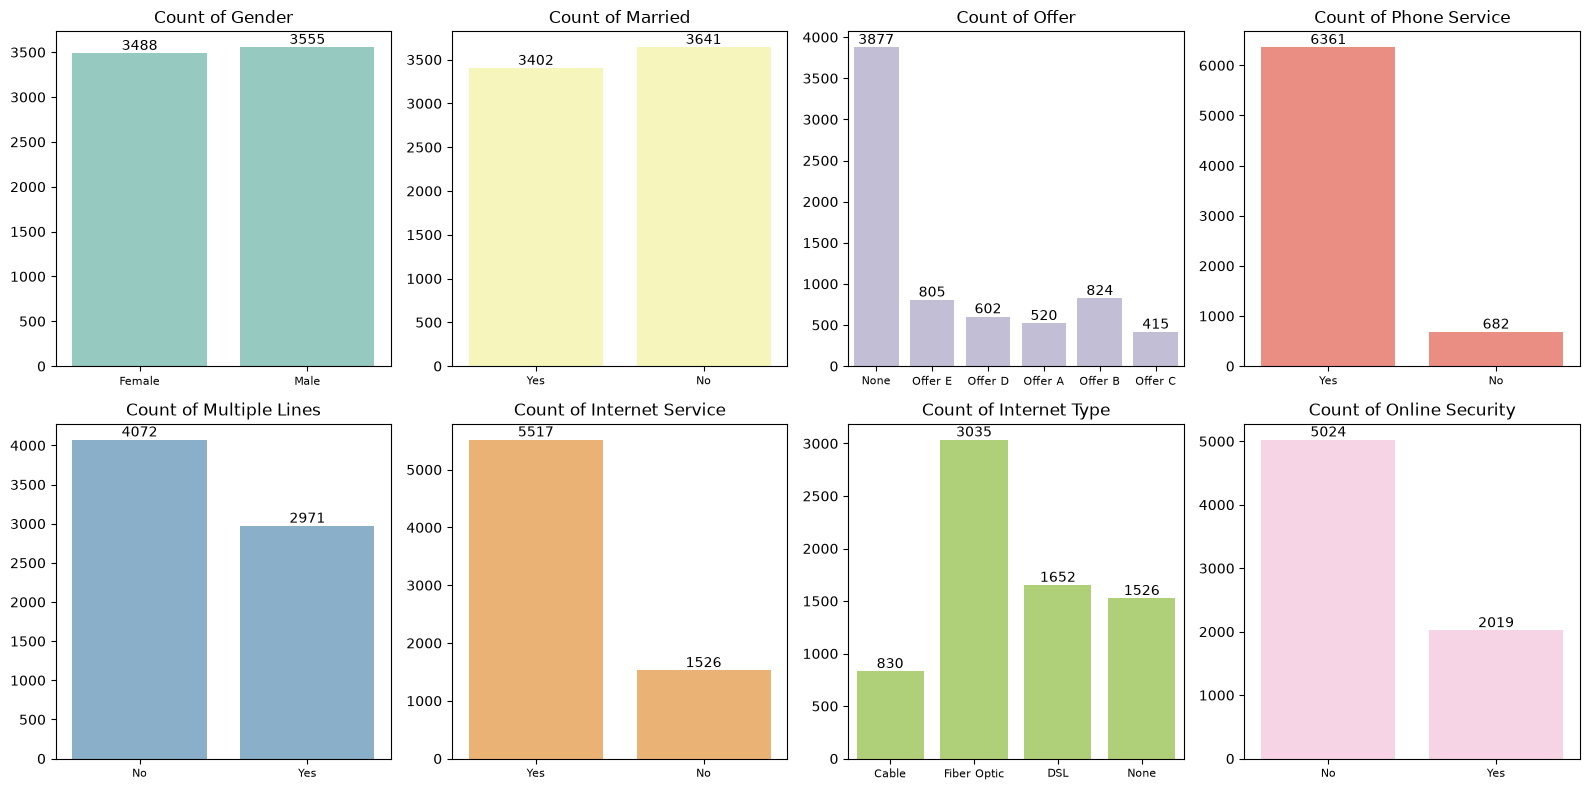

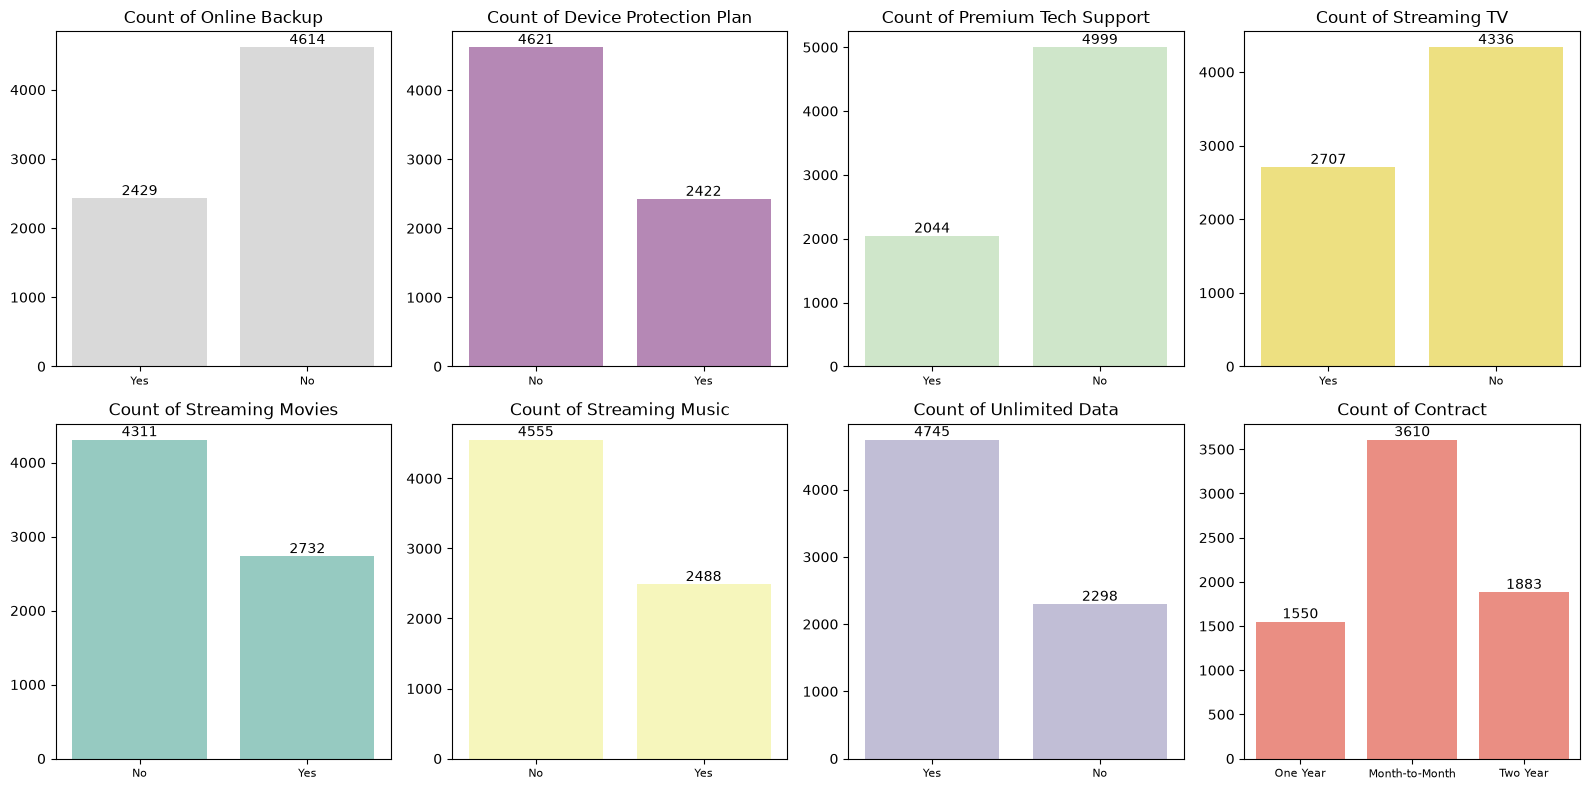

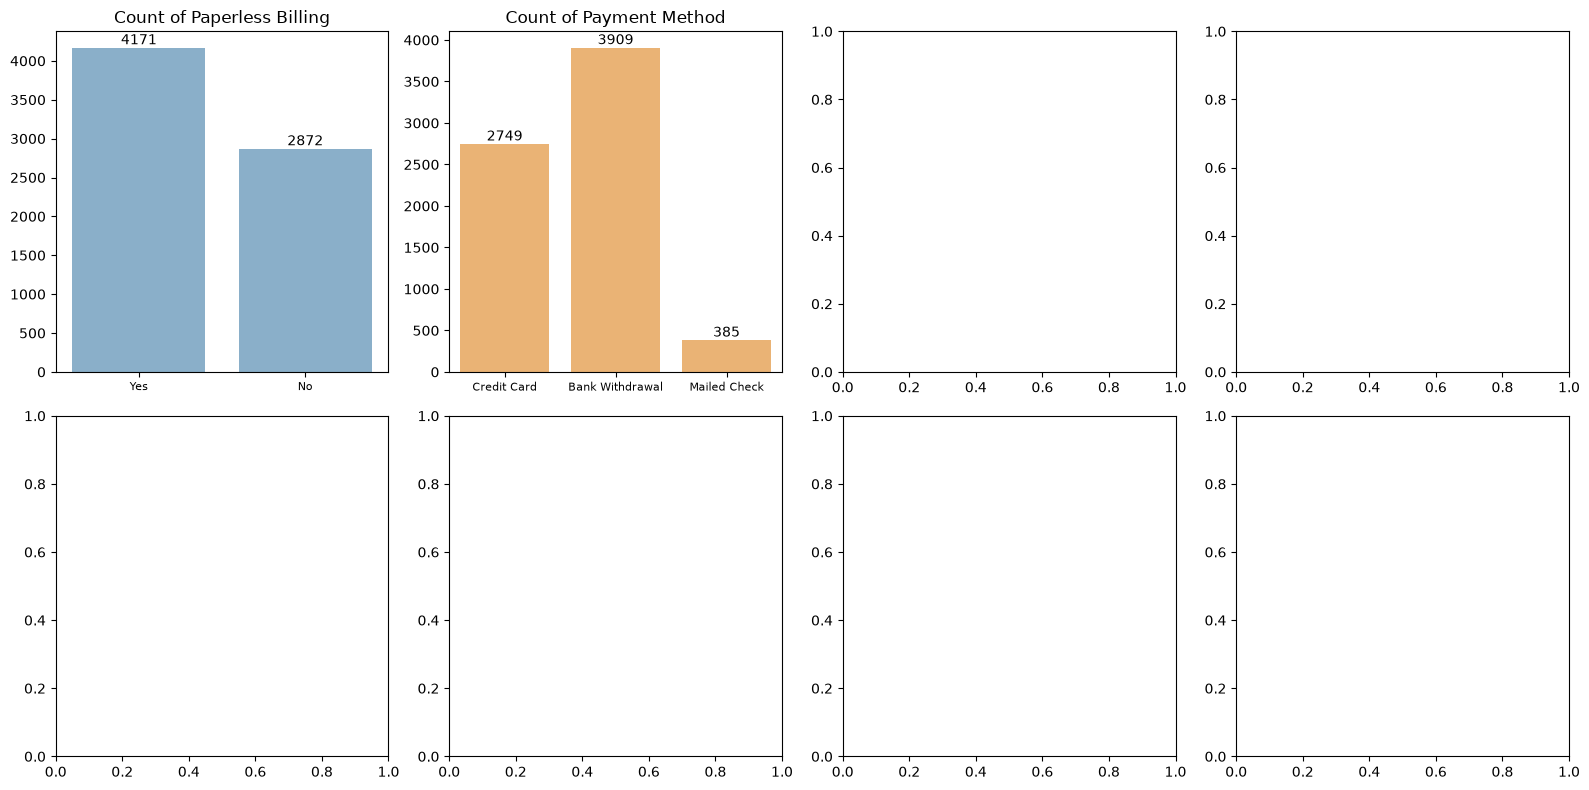

------Feature Imbalance (>0.7)------
Phone Service
Internet Service
Online Security
Premium Tech Support


In [13]:
colors = sns.color_palette('Set3', len(modified_cat_cols))

fig, axes = plt.subplots(2,4, figsize=(16,8))
i,j = 0,0
count = 0

modified_cat_cols_2 = [x for x in modified_cat_cols if x not in ['Customer Status', 'Churn Reason', 'Churn Category']]

for col in modified_cat_cols_2: 
    sns.countplot(data=df, x= col, color=colors[count], ax=axes[i,j])
    axes[i,j].set_title(f'Count of {col}')
    axes[i,j].set_ylabel('')
    axes[i,j].set_xlabel('')
    axes[i,j].tick_params(axis='x', labelsize=8)

    for container in axes[i,j].containers:
        axes[i,j].bar_label(container)

    count+=1
    j +=1
    if j==4:
        i +=1
        j = 0
    if i==2:
        plt.tight_layout()
        plt.show()
        if count == len(modified_cat_cols_2):
            break
        fig, axes = plt.subplots(2,4, figsize=(16,8))
        i,j =0,0
if count % 8 != 0:
    plt.tight_layout()
    plt.show()


col_feature_imbalance = []
for col in modified_cat_cols_2:
    df_temp = df[col].value_counts(normalize=True)
    if df_temp.iloc[0]>0.7:
        col_feature_imbalance.append(col)

print('------Feature Imbalance (>0.7)------')
print(*col_feature_imbalance,sep='\n')


    

#### Overview

Overall, Offer, Phone Service, Internet Service, Online Security and Premium Tech Support have some level of imbalance:

1. Most customers do not accept an Offer.
2. Most customers subscribed to a phone service.
3. Most customers subscribed to an internet service.
4. Most customers opt out of paying for online security.
5. Most customers opt out of paying for premium tech support.


### Part 2: Identifying Target imbalance 

The goal is to identify target imbalance of Customer Stats. According to [(Lluis, 2025)](https://medium.com/@masdeu.lluis/dealing-with-class-imbalance-in-classification-models-fd127f09dddc), target imbalance is when the dependent variable has an uneven class representation. This requires attention as models can be biased toward the majority class. 

Before that, joined customers wil be removed from the dataset, because they are not part of the starting customer base before the period. Including them in the dataset could distort analysis.

In [14]:
result = df['Customer Status'].value_counts()
try:
    print('---------Customer Status Proportion---------')
    print(f'{result}\n')
    print(f'Number of joined customers is {result['Joined']}.')
    print(f'Proportion of joined customers is {(result['Joined']/len(df))*100:.2f}%.')
except:
    print('Joined customers already removed!')

---------Customer Status Proportion---------
Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

Number of joined customers is 454.
Proportion of joined customers is 6.45%.


In [15]:
df_joined = df[df['Customer Status']=='Joined']
df = df[df['Customer Status']!='Joined']
print('Joined Customer removed!')
print(f'Dataset now has {len(df)} observations after removing {len(df_joined)} worth of joined customers.\n')
dataset_check(df)


Joined Customer removed!
Dataset now has 6589 observations after removing 454 worth of joined customers.

-----------------Info-----------------
Shape: (6589, 38)
Size: 250382
Observations: 6589
Dimension: 2

-----------------Datatype-----------------
Customer ID                              str
Gender                                   str
Age                                    int64
Married                                  str
Number of Dependents                   int64
City                                     str
Zip Code                               int64
Latitude                             float64
Longitude                            float64
Number of Referrals                    int64
Tenure in Months                       int64
Offer                                    str
Phone Service                            str
Avg Monthly Long Distance Charges    float64
Multiple Lines                           str
Internet Service                         str
Internet Type               

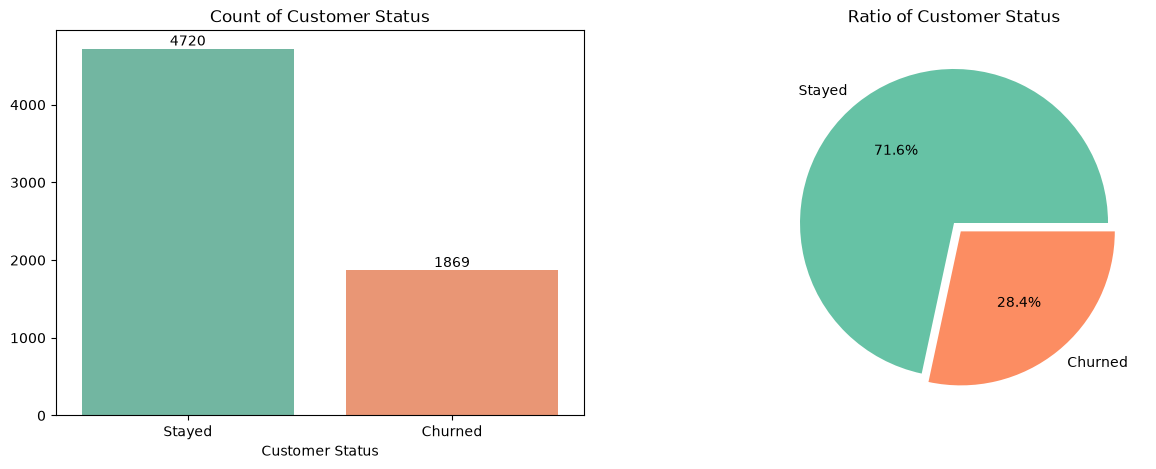

In [16]:
colors = sns.color_palette('Set2')

df_temp = df['Customer Status'].value_counts()

fig, axes = plt.subplots(1,2, figsize=(15,5))
sns.countplot(data=df, x='Customer Status', hue='Customer Status', palette='Set2', legend=False, ax=axes[0])
axes[0].set_ylabel('')
axes[0].set_title(f'Count of Customer Status')
for container in axes[0].containers:
        axes[0].bar_label(container)

axes[1].pie(df_temp,explode=[0,0.07], labels=df_temp.index, colors=[colors[0],colors[1]], autopct='%1.1f%%')
axes[1].set_title(f'Ratio of Customer Status')
plt.savefig('images/customer_status_ratio.png', bbox_inches='tight',dpi=300)
plt.show()

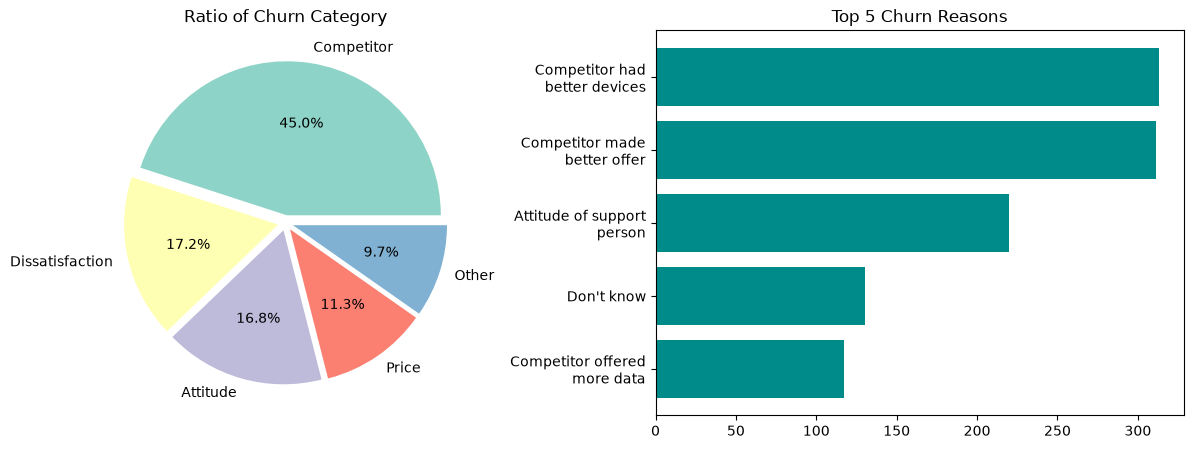

In [17]:
import textwrap

colors = sns.color_palette('Set3')

df_temp = df['Churn Category'].value_counts().iloc[1:]
df_temp2 = df['Churn Reason'].value_counts().iloc[1:].sort_values().tail()

wrapped_labels = [textwrap.fill(label, width=20) for label in df_temp2.index]

fig, axes = plt.subplots(1,2, figsize=(15,5))

axes[0].pie(df_temp,explode=[0.05]*len(df_temp), labels=df_temp.index, colors=[colors[0],colors[1],colors[2],colors[3],colors[4]], autopct='%1.1f%%')
axes[0].set_title(f'Ratio of Churn Category')

axes[1].barh(y=wrapped_labels, width=df_temp2.values, color='darkcyan')
axes[1].set_title(f'Top 5 Churn Reasons')

plt.savefig('images/churn_category_reasons.png', bbox_inches='tight',dpi=300)
plt.show()

#### Overview

Customers that stayed represented 71.6% of the dataset, a clear indication of target imbalance. Also, churned customers left mostly due to competitor superior products and offers, followed closely by dissatisfaction with the company's customer support.

Therefore, target imbalance will be addressed later on via downsampling or upsampling.

## 5. Handling correlation: Correlation Matrix

If multicollinearity exists, that it can negatively impact the performance of linear models. However, since I plan to use a Random Forest model, which according to [(Mane, 2021)](https://medium.com/@manepriyanka48/multicollinearity-in-tree-based-models-b971292db140), multicollinearity would not impact the prediction performance of the model.

However, it would still be useful to identify redundent variables and remove them from feature selection. According to [Kubus (2019)](https://doi.org/10.18778/0208-6018.339.01), there would be a decrease of classification acuracy if redundant varaibles are introduced.

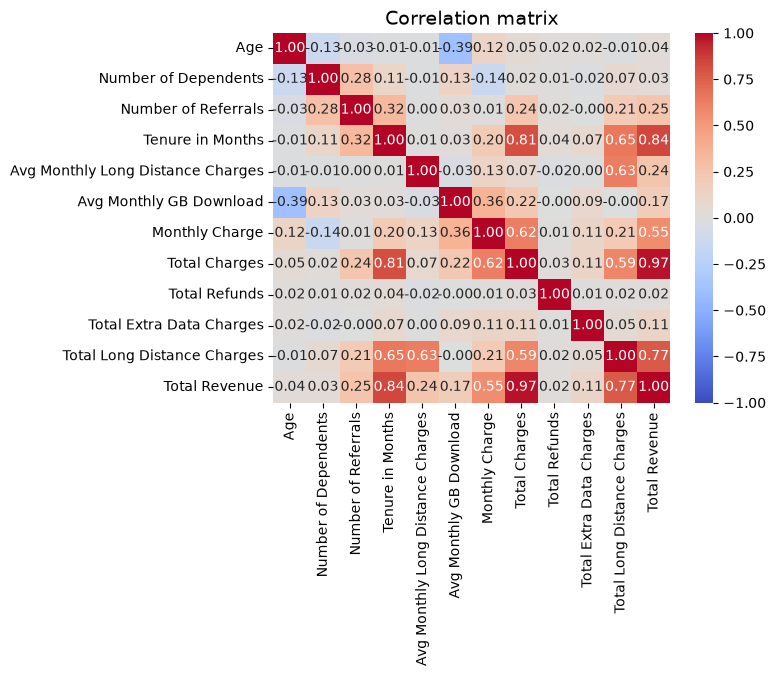

---------------Pairs with > 0.7 corr---------------
Total Charges                Total Revenue    0.97
Tenure in Months             Total Revenue    0.84
                             Total Charges    0.81
Total Long Distance Charges  Total Revenue    0.77
dtype: float64

---------------Pairs with > 0.5 corr---------------
Tenure in Months                   Total Long Distance Charges    0.65
Avg Monthly Long Distance Charges  Total Long Distance Charges    0.63
Monthly Charge                     Total Charges                  0.62
Total Charges                      Total Long Distance Charges    0.59
Monthly Charge                     Total Revenue                  0.55
dtype: float64


In [18]:
corr = df[modified_num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix', fontsize=14)
plt.savefig('images/correlation_matrix.png', bbox_inches='tight',dpi=300)
plt.show()

upper = corr.abs().where(np.triu(np.ones(corr.abs().shape, dtype=bool), k=1))
pairs = upper.stack().dropna().sort_values(ascending=False)
print('---------------Pairs with > 0.7 corr---------------')
print(pairs[pairs > 0.7].round(2))
print()

print('---------------Pairs with > 0.5 corr---------------')
print(pairs[(pairs > 0.5) & (pairs <0.7)].round(2))


#### Overview

As expected, the top few highly correlated pairs above absolute value of 0.7 all come from the derived variable Total Revenue, which is calulated by Total Charge - Total Refunds + Total Extra Data Charges + Total Long Distance Charges. In fact, Total Revenue has 0.97 correlation with Total Charge, which has a 0.81 correlation with Tenure in Months, which is expected. 
 
Besides that, other notable correlational pairs are the following:

- Tenure in Months & Total Long Distance Charges: <u>0.653170</u>
- Avg Monthly Long Distance Charges & Total Long Distance Charges: <u>0.630419</u>
- Monthly Charge & Total Charges: <u>0.619024</u>
- Total Charges & Total Long Distance Charges: <u>0.587375</u>
- Monthly Charge & Total Revenue: <u>0.554815</u>


As removing features to avoid multicollinearity is less crucial for tree-based models. Therefore, I decided to keep them in the model to improve performance. 

## 6. Feature Engineering: Customer Segmentation by tenure and age

The goal is to uncover hidde churn patterns by grouping customers into similar traits. Before that, I will define a new column called `Churn Binary` to binary map Customer Status.

In [19]:
df['Churn Binary'] = (df['Customer Status']=='Churned').astype(int)
df['Churn Binary'].unique()

array([0, 1])

In [20]:
def age_mapping(age):
    if age <=25:
        return 'Youth (19-25 years)'
    elif age <=44:
        return 'Young Adults (26-44 years)'
    elif age <= 59:
        return 'Middle Age (45-59 years)'
    elif age <= 74:
        return 'Elderly (60-74 years)'
    elif age >74:
        return 'Senior (75+ years)'

df['Age Group'] = df['Age'].apply(age_mapping)
df['Age Group'].unique()



<ArrowStringArray>
['Young Adults (26-44 years)',   'Middle Age (45-59 years)',
         'Senior (75+ years)',        'Youth (19-25 years)',
      'Elderly (60-74 years)']
Length: 5, dtype: str

In [21]:
def tenure_mapping(tenure):
    if tenure <= 6:
        return 'Newbie (0-6 months)'
    elif tenure <=12:
        return 'Early bird (7-12 months)'
    elif tenure <=24:
        return 'Established (13-24 months)'
    elif tenure <= 48:
        return 'Long-term (25-48 months)'
    elif tenure > 48:
        return 'Loyalist (>48 months)'

df['Tenure Group'] = df['Tenure in Months'].apply(tenure_mapping)
df['Tenure Group'].unique()

<ArrowStringArray>
[  'Early bird (7-12 months)',        'Newbie (0-6 months)',
 'Established (13-24 months)',      'Loyalist (>48 months)',
   'Long-term (25-48 months)']
Length: 5, dtype: str

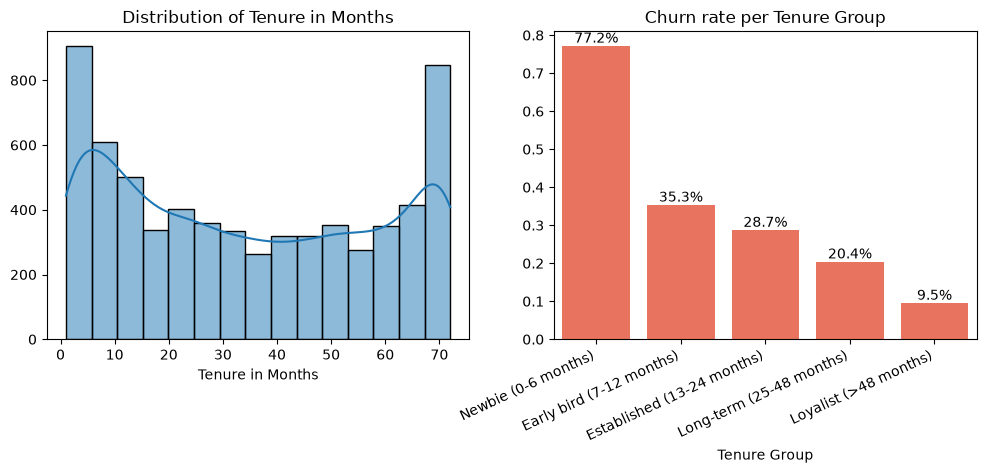

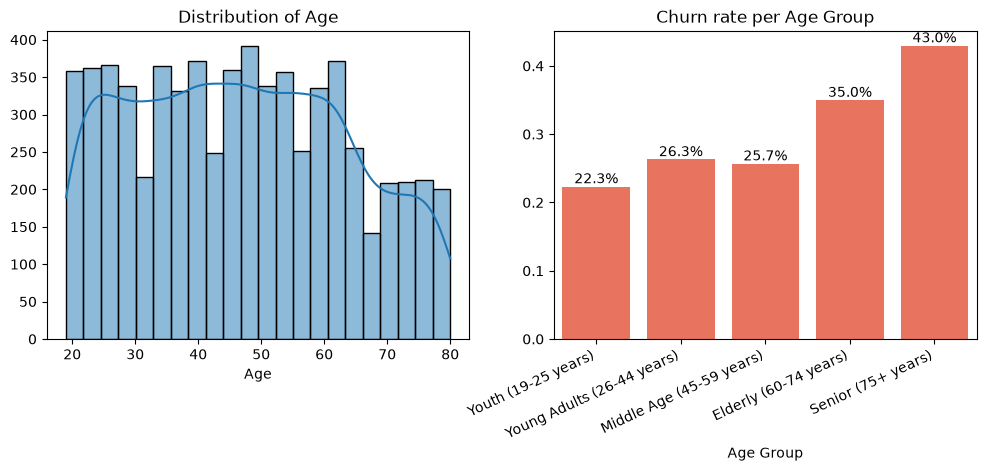

In [22]:
order_list_tenure = ['Newbie (0-6 months)', 'Early bird (7-12 months)', 'Established (13-24 months)', 'Long-term (25-48 months)', 'Loyalist (>48 months)' ]
order_list_age = ['Youth (19-25 years)', 'Young Adults (26-44 years)', 'Middle Age (45-59 years)', 'Elderly (60-74 years)', 'Senior (75+ years)']

order_list = [order_list_tenure, order_list_age]
grouped_list = ['Tenure Group', 'Age Group']
bin_list = ['Tenure in Months', 'Age']

fig, axes = plt.subplots(1,2, figsize=(12,4))
count=0

for n in range(len(grouped_list)):
    m = len(df[bin_list[n]])
    col_max = df[bin_list[n]].max()
    col_min = df[bin_list[n]].min()
    col_Q1, col_Q3 = df[bin_list[n]].quantile([0.25, 0.75])
    col_IQR = col_Q3 - col_Q1
    bin_width = 2*col_IQR/ (m**(1/3))
    bin_num = int(np.ceil((col_max - col_min)/bin_width))
    sns.histplot(data=df, x=bin_list[n], bins=bin_num, kde=True, ax=axes[0])
    
    
    
    df_plot = (
        df
        .groupby(grouped_list[n], as_index=False)['Churn Binary']
        .mean()
    )
    sns.barplot(
        data=df_plot,
        x=grouped_list[n],
        y='Churn Binary',
        order=order_list[n],
        color='tomato',
        ax=axes[1]
    )   
    for container in axes[1].containers:
        label = [f'{v.get_height()*100:.1f}%' for v in container]
        axes[1].bar_label(container, labels=label )
    

    count+=1
    axes[0].set_title(f'Distribution of {bin_list[n]}')
    axes[0].set_ylabel('')

    axes[1].set_title(f'Churn rate per {grouped_list[n]}')
    axes[1].tick_params(axis='x', labelrotation=25)
    axes[1].set_ylabel('')
    plt.setp(axes[1].get_xticklabels(), ha='right')
    plt.savefig(f'images/churn_rate_{["tenure","age"][n]}.png', bbox_inches='tight', dpi=300)
    plt.show()

    if count==len(grouped_list):
        break
    fig, axes = plt.subplots(1,2, figsize=(12,4))



#### Overview

It can be seen that newer customers have a high churn rate of 77.1%, while long-term customers around. Among the age group, it would seem that seniors also tend to have a higher churn rate than the rest, but not by too much.

This thus presents a need to dig deeper to find out why customers churn.

## 7. Feature Engineering: Categorical Encoding

The goal is encode categorical varialbles to 0 if 'No' or 'None', and 1 otherwise. Categorical variables types are as such:

1. Nominal with only two unique values (i.e. Yes or No, Male or Female) will be binary encoded.
2. Nominal with more than two unique values will be one-hot-encoded. New columns will be created for every unique values it has.


In [23]:
for col in modified_cat_cols_2:
    print(f'-------{len(df[col].unique())} values in {col}-------')
    for value in df[col].unique():
        print(value, end=' ')
    print('\n')

-------2 values in Gender-------
Female Male 

-------2 values in Married-------
Yes No 

-------6 values in Offer-------
None Offer E Offer D Offer A Offer B Offer C 

-------2 values in Phone Service-------
Yes No 

-------2 values in Multiple Lines-------
No Yes 

-------2 values in Internet Service-------
Yes No 

-------4 values in Internet Type-------
Cable Fiber Optic DSL None 

-------2 values in Online Security-------
No Yes 

-------2 values in Online Backup-------
Yes No 

-------2 values in Device Protection Plan-------
No Yes 

-------2 values in Premium Tech Support-------
Yes No 

-------2 values in Streaming TV-------
Yes No 

-------2 values in Streaming Movies-------
No Yes 

-------2 values in Streaming Music-------
No Yes 

-------2 values in Unlimited Data-------
Yes No 

-------3 values in Contract-------
One Year Month-to-Month Two Year 

-------2 values in Paperless Billing-------
Yes No 

-------3 values in Payment Method-------
Credit Card Bank Withdrawal Mail

In [24]:
df_model = pd.DataFrame()

df_model = pd.get_dummies(df[['Offer', 'Internet Type', 'Contract', 'Payment Method', 'Age Group', 'Tenure Group']], 
            columns=['Offer', 'Internet Type', 'Contract', 'Payment Method', 'Age Group', 'Tenure Group'], 
            dtype=int)

for col in modified_cat_cols_2:
    if len(df[col].unique())==2:
        if 'Yes' in df[col].unique():
            df_model[col] = (df[col]=='Yes').astype(int)
        elif 'Male' in df[col].unique():
            df_model[col] = (df[col]=='Male').astype(int)

for col in modified_num_cols + ['Churn Binary']:
    df_model[col] = df[col]
df_model.columns

print('-------------Summary of df_model-------------')
print(f'Shape: {df_model.shape}')
print(f'Number of features: {len(df_model.columns)-1}\n')
      
print('-------------Number of Categorical features-------------')
print(f'Before encoding: {len(modified_cat_cols_2)}')
print(f'After encoding: {len(modified_cat_cols_2)-4+6+4+3+3}')

#14 nominal variable that requred binary encoding, and 4 variable that required one-hot-encoding, 1 column per number of unique values.
# (i.e. 6 unique values, 4 unique values, 2x 3 unique value)





-------------Summary of df_model-------------
Shape: (6589, 53)
Number of features: 52

-------------Number of Categorical features-------------
Before encoding: 18
After encoding: 30


#### Overview

`df_model` now contains encoded categorical variables (both features and target) and the original numerical feature variables. Total number of features is 42. 

The dataset is ready for modelling.

---
# Modelling: Random Forest

This project focuses exclusively on Random Forest models, with each iteration designed to improve predictive performance. The goal is to first create a baseline model without any modifications, and improve upon it step by step by increasing its predictive power based on a select set of evaluation metrics.

 According to [Jones (2025)](https://medium.com/@duygujones/classification-metrics-choosing-the-right-metrics-for-your-ml-models-87bf996d7c93), there are a number of metrics that classfication models are evaluated on, such as `Accuracy`, `Precision`, `Recall`, `F1-Score` and `AUC-ROC`. 

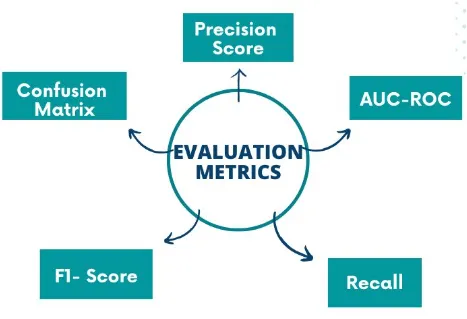

 
 However, for this project, I reasoned that the <u>cost of a false negative</u> (i.e. a customer predicted to stay to stay turns out to churn later) is much more costly then the <u>cost of a false positive</u> (i.e. a customer predicted to churn who never intended to leave). This is because the cost of retention is far less than the loss of revenue from the customer that churns. 
 
Therefore, <b>recall</b> will be the primary metric to evaluate and compare models, but not sacrificing precision too, as the model should also predict churned customers correct as often as possible.

Overall, the metrics used to evaluate are:
 1. Recall = TP/ (TP + FN) 
 2. Precision = TP/ (TP + FP)
 3. F1 score = 2*(precision*recall)/ (precision + recall)
 5.  ROC-AUC (Receiver Operating Characteristic - Area Under Curve)
 6. PR-AUC (Precision-Recall Area Under Curve)

### 1. Baseline model

In [25]:
df_baseline = df_model.drop(['Age Group_Elderly (60-74 years)',
       'Age Group_Middle Age (45-59 years)', 'Age Group_Senior (75+ years)',
       'Age Group_Young Adults (26-44 years)', 'Age Group_Youth (19-25 years)',
       'Tenure Group_Early bird (7-12 months)',
       'Tenure Group_Established (13-24 months)',
       'Tenure Group_Long-term (25-48 months)',
       'Tenure Group_Loyalist (>48 months)',
       'Tenure Group_Newbie (0-6 months)'], axis=1).copy()
df_baseline.columns

Index(['Offer_None', 'Offer_Offer A', 'Offer_Offer B', 'Offer_Offer C',
       'Offer_Offer D', 'Offer_Offer E', 'Internet Type_Cable',
       'Internet Type_DSL', 'Internet Type_Fiber Optic', 'Internet Type_None',
       'Contract_Month-to-Month', 'Contract_One Year', 'Contract_Two Year',
       'Payment Method_Bank Withdrawal', 'Payment Method_Credit Card',
       'Payment Method_Mailed Check', 'Gender', 'Married', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection Plan', 'Premium Tech Support',
       'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data',
       'Paperless Billing', 'Age', 'Number of Dependents',
       'Number of Referrals', 'Tenure in Months',
       'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download',
       'Monthly Charge', 'Total Charges', 'Total Refunds',
       'Total Extra Data Charges', 'Total Long Distance Charges',
       'Total Revenue', 'Churn Binary']

In [26]:
#this cell imports all libraries
from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict, StratifiedKFold,  GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
   precision_score, recall_score, f1_score,
   classification_report, confusion_matrix,
   roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

from itertools import permutations

from boruta import BorutaPy

import time


In [27]:
seed = 42
X = df_baseline.drop('Churn Binary', axis=1)
y = df_baseline['Churn Binary']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state=seed, stratify=y)

              precision    recall  f1-score   support

           0       0.89      0.95      0.92      3776
           1       0.84      0.69      0.76      1495

    accuracy                           0.87      5271
   macro avg       0.86      0.82      0.84      5271
weighted avg       0.87      0.87      0.87      5271

Baseline Results:
✅ Recall: 0.6876
✅ Precision: 0.8412
✅ F1 score: 0.7562
✅ ROC-AUC: 0.93
✅ PR-AUC: 0.87


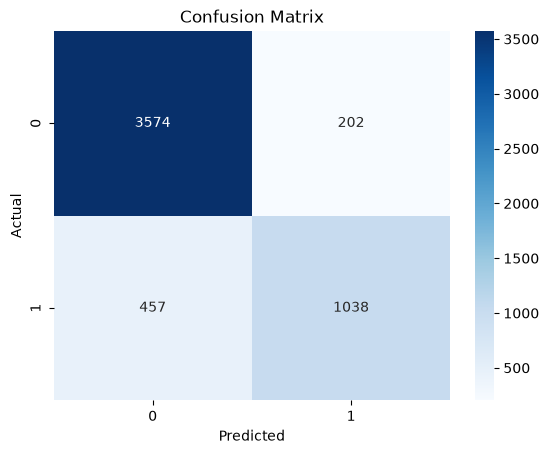

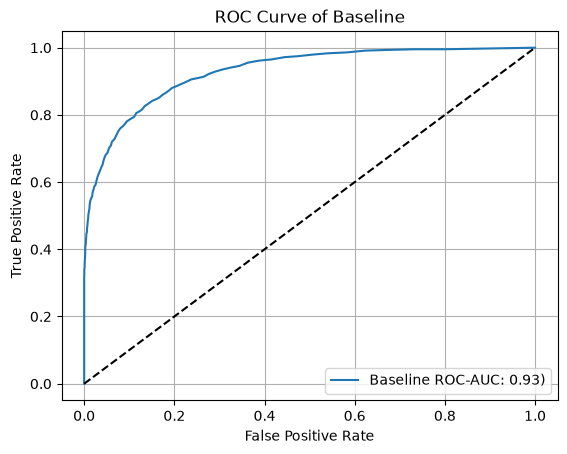

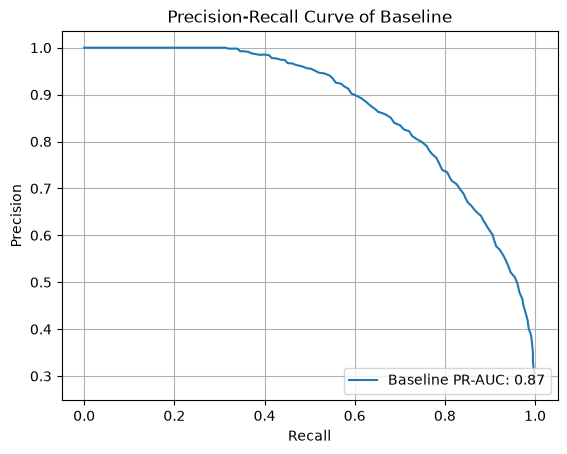

In [28]:
#using CV

def get_baseline_metrics(X_train, y_train):

    #define empty dictionary and list to store results.
    plot_results = {}
    metric_results = []
    
    rf_model = RandomForestClassifier(random_state=seed)              
    cv_results = cross_validate(rf_model, X_train, y_train, cv=5, scoring=['recall', 'precision', 'f1', 'roc_auc', 'average_precision'])
    val_recall = round(cv_results['test_recall'].mean(), 4)
    val_precision = round(cv_results['test_precision'].mean(), 4)
    val_f1 = round(cv_results['test_f1'].mean(), 4)
    val_roc_auc = round(cv_results['test_roc_auc'].mean(), 2)
    val_pr_auc = round(cv_results['test_average_precision'].mean(), 2)

    # Out-of-fold predicted probabilities for the training data
    y_prob = cross_val_predict(rf_model, X_train, y_train, cv=5, method='predict_proba')[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    #Calculate ROC and precision-recall curve points
    fpr_rf, tpr_rf, _ = roc_curve(y_train, y_prob)
    precision_plot, recall_plot, _ = precision_recall_curve(y_train, y_prob)

    rf_params = rf_model.get_params()

    #store values for ROC curve and PR curve plot
    plot_results['baseline'] = {
        'y_pred' : y_pred,
        'y_prob' : y_prob,
        'fpr': fpr_rf,
        'tpr': tpr_rf,
        'precision_plot': precision_plot,
        'recall_plot': recall_plot
    }

    # store validation scores.
    metric_results.append({
            'model_name' : 'baseline',
            'recall' : val_recall,
            'precision' : val_precision,
            'f1' : val_f1,
            'roc_auc': val_roc_auc,
            'pr_auc': val_pr_auc,
            'final_model': rf_model,
            'rf_params' : rf_params
    })

    return plot_results, metric_results


#################################################################################
#Running function to retrieve results and print metrics + charts
baseline_plot_results, baseline_metric_results = get_baseline_metrics(X_train, y_train)

print(classification_report(y_train, baseline_plot_results['baseline']['y_pred']))

print(f'Baseline Results:')
print(f'✅ Recall: {baseline_metric_results[0]['recall']:.4f}')
print(f'✅ Precision: {baseline_metric_results[0]['precision']:.4f}')
print(f'✅ F1 score: {baseline_metric_results[0]['f1']:.4f}')
print(f'✅ ROC-AUC: {baseline_metric_results[0]['roc_auc']:.2f}')
print(f'✅ PR-AUC: {baseline_metric_results[0]['pr_auc']:.2f}')

#plot confusion matrix
rf_matrix = confusion_matrix(y_train, baseline_plot_results['baseline']['y_pred'])
sns.heatmap(pd.DataFrame(rf_matrix), annot=True, fmt='.0f', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig(f'images/baseline_confusion_matrix.png', bbox_inches='tight', dpi=300)
plt.show()

#plot ROC Curve
plt.plot(baseline_plot_results['baseline']['fpr'], baseline_plot_results['baseline']['tpr'], label=f'Baseline ROC-AUC: {baseline_metric_results[0]['roc_auc']:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve of Baseline')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

#plot Precision-Recall Curve
plt.plot(baseline_plot_results['baseline']['recall_plot'], baseline_plot_results['baseline']['precision_plot'], label=f'Baseline PR-AUC: {baseline_metric_results[0]['pr_auc']:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve of Baseline')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


#### Oveview

Overall, the baseline RandomForest model shows some average validation scores of `recall = 0.6876`, `precision = 0.8412` and `F1 score = 0.7562`. It has a `ROC-AUC = 0.93` and `PR-AUC = 0.87`. 

Next, I explore some steps to improve these metrics (primarly recall) by:
1. introducing more engineered features based on domain knowlesge
2. target imbalance handling (undersample vs oversample)
3. variable selection (boruta vs importance feature)
4. cross validation to tune hyperparameters (validation vs 10-fold CV)

## 2. Model improvements

The goal is to improve the predictive model of the baseline. 

1. Introducing engineered features
2. Handling target imbalance: downsampling/ upsampling
3. Variable selection: important features/ Boruta method
4. Hyperparameter tuning: RandomisedSearchCV

It may be possible to improve the model by introducing engineered features based on domain knowledge. Also, from EDA analysis, it is revealed that there is target imbalance, hence a resampling method is used. Finally, to address the issue of overfitting, I may explore the use of varialbe selection to reduce the number of features, and RandomisdSearchCV with `min_sample_leaf` to analyse the parameters with least training-validation score spread.

Ideally, I would test out all possible valid combinations and pick the one with the best scores. For now, however, I will only prepare one model

`Engineered features and downsampling inside RandomisedSearchCV`
 

However, according to this source https://www.cambridge.org/core/journals/political-analysis/article/how-crossvalidation-can-go-wrong-and-what-to-do-about-it/CA8C4B470E27C99892AB978CE0A3AE29, it seems like I need to downsample inside the cross validation loop and not before it to prevent data leakage. 

Hence, I will createa pipeline for this.


In [29]:
def do_eng_features(X_train):
   df_temp = df_model[['Age Group_Elderly (60-74 years)',
      'Age Group_Middle Age (45-59 years)', 'Age Group_Senior (75+ years)',
      'Age Group_Young Adults (26-44 years)', 'Age Group_Youth (19-25 years)',
      'Tenure Group_Early bird (7-12 months)',
      'Tenure Group_Established (13-24 months)',
      'Tenure Group_Long-term (25-48 months)',
      'Tenure Group_Loyalist (>48 months)',
      'Tenure Group_Newbie (0-6 months)']].copy()

   df_train = df_temp.loc[X_train.index]

   X_train_eng_fea = pd.concat([df_train, X_train], axis=1)

   return X_train_eng_fea

In [30]:
rs_params = {"n_estimators": [int(x) for x in np.linspace(start = 200, stop = 2000, num = 10)],
             "max_depth": [int(x) for x in np.linspace(10, 110, num = 9)]+[None],
             "min_samples_split": [2, 5, 8],
             "min_samples_leaf": [1, 3, 5, 10, 15, 20],
             "max_features": [int(x) for x in np.linspace(start = 3, stop = 10, num = 4)]+['sqrt']
             }

Baseline---------vs---------Improved
✅ recall: 0.6876	->	0.8301
✅ precision: 0.8412	->	0.6911
✅ f1: 0.7562	->	0.7540
✅ roc_auc: 0.9300	->	0.9256
✅ pr_auc: 0.8700	->	0.8632

              precision    recall  f1-score   support

           0       0.93      0.85      0.89      3776
           1       0.69      0.83      0.75      1495

    accuracy                           0.85      5271
   macro avg       0.81      0.84      0.82      5271
weighted avg       0.86      0.85      0.85      5271



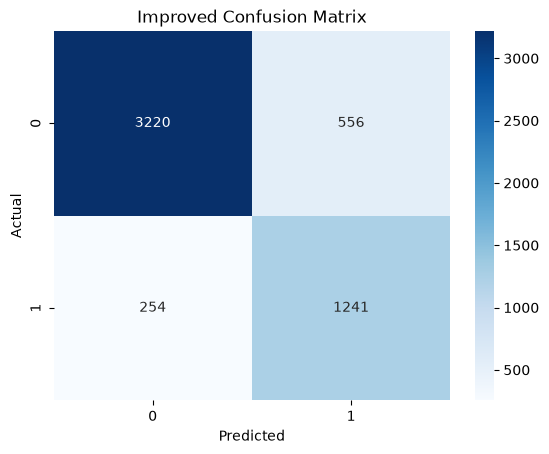

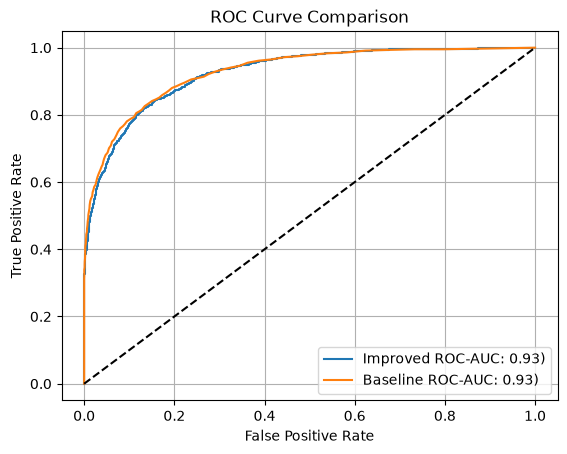

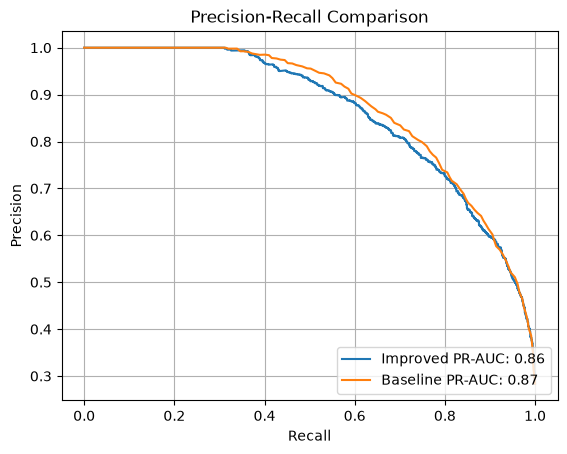

In [31]:
def get_improved_metrics(X_train, y_train):
    seed = 42
    #define empty dictionary and list to store results.
    plot_results = {}
    metric_results = []

    X_train = do_eng_features(X_train)
    
    pipeline = ImbPipeline([
    ('sampler', RandomUnderSampler(random_state=seed)),
    ('classifier', RandomForestClassifier(random_state=seed))])
    
    rs_cv = RandomizedSearchCV(
                    pipeline,  
                    param_distributions= {f'classifier__{param}': values for param, values in rs_params.items()},
                    n_iter=5,
                    cv=5,
                    scoring={
                        'recall': 'recall',
                        'precision': 'precision',
                        'f1': 'f1',
                        'roc_auc': 'roc_auc',
                        'average_precision': 'average_precision'
                    },
                    refit='f1',
                    n_jobs=-1,
                    verbose=0,
                    random_state=42,
                    error_score='raise',
                    return_train_score=True
                )
    
    rs_cv.fit(X_train, y_train)

    # 4. Retrieving mean validation scores
    best_idx = rs_cv.best_index_
    search_results = rs_cv.cv_results_

    val_recall = round(
        search_results['mean_test_recall'][best_idx], 4
    )
    val_precision = round(
        search_results['mean_test_precision'][best_idx], 4
    )
    val_f1 = round(
        search_results['mean_test_f1'][best_idx], 4
    )
    val_roc_auc = round(
        search_results['mean_test_roc_auc'][best_idx], 4
    )
    val_pr_auc = round(
        search_results['mean_test_average_precision'][best_idx], 4
    )

    # 5. Fit the model on all training data
    best_params = rs_cv.best_params_
    final_model = rs_cv.best_estimator_

    # 6. Retrieving Out-of-fold predicted probabilities for the training data. Also retrieve ROC and precision-recall curve points
    y_prob = cross_val_predict(final_model, X_train, y_train, cv=5, method='predict_proba')[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    fpr_rf, tpr_rf, _ = roc_curve(y_train, y_prob)
    precision_plot, recall_plot, _ = precision_recall_curve(y_train, y_prob)

    # 7. Store mean validation scores for ranking 
    metric_results.append({
            'model_name' : 'improved',
            'recall' : val_recall,
            'precision' : val_precision,
            'f1' : val_f1,
            'roc_auc': val_roc_auc,
            'pr_auc': val_pr_auc,
            'final_model': final_model,
            'rf_params' : best_params,
            'CV_output' : rs_cv
    })

    # 8. Store values for ROC curve and PR curve plot
    plot_results['improved'] = {
        'y_pred' : y_pred,
        'y_prob' : y_prob,
        'fpr': fpr_rf,
        'tpr': tpr_rf,
        'precision_plot': precision_plot,
        'recall_plot': recall_plot,
    }
              


    return plot_results, metric_results


#################################################################################
#Running function to retrieve results and print metrics + charts
improved_plot_results, improved_metric_results = get_improved_metrics(X_train, y_train)


metrics = ['recall', 'precision' , 'f1' , 'roc_auc', 'pr_auc']

print(f'Baseline---------vs---------Improved')
for metric in metrics:
    print(f'✅ {metric}: '
          f'{baseline_metric_results[0][metric]:.4f}'
          f'\t->\t'
          f'{improved_metric_results[0][metric]:.4f}')

print()
print(classification_report(y_train, improved_plot_results['improved']['y_pred']))

#plot confusion matrix
rf_matrix = confusion_matrix(y_train, improved_plot_results['improved']['y_pred'])
sns.heatmap(pd.DataFrame(rf_matrix), annot=True, fmt='.0f', cmap='Blues')
plt.title('Improved Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig(f'images/improved_confusion_matrix.png', bbox_inches='tight', dpi=300)
plt.show()

#plot ROC Curve
plt.plot(improved_plot_results['improved']['fpr'], improved_plot_results['improved']['tpr'], label=f'Improved ROC-AUC: {improved_metric_results[0]['roc_auc']:.2f})')
plt.plot(baseline_plot_results['baseline']['fpr'], baseline_plot_results['baseline']['tpr'], label=f'Baseline ROC-AUC: {baseline_metric_results[0]['roc_auc']:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig(f'images/roc_comparison.png', bbox_inches='tight', dpi=300)
plt.show()

#plot Precision-Recall Curve
plt.plot(improved_plot_results['improved']['recall_plot'], improved_plot_results['improved']['precision_plot'], label=f'Improved PR-AUC: {improved_metric_results[0]['pr_auc']:.2f}')
plt.plot(baseline_plot_results['baseline']['recall_plot'], baseline_plot_results['baseline']['precision_plot'], label=f'Baseline PR-AUC: {baseline_metric_results[0]['pr_auc']:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Comparison')
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig(f'images/pr_comparison.png', bbox_inches='tight', dpi=300)
plt.show()

In [32]:
#checking for overfitting and underfitting
metrics = ['recall', 'precision' , 'f1' , 'roc_auc', 'average_precision']

rs_cv = improved_metric_results[0]['CV_output']
results = pd.DataFrame(rs_cv.cv_results_)

for metric in metrics:
    val_score = results.loc[rs_cv.best_index_, f'mean_test_{metric}']
    train_score = results.loc[rs_cv.best_index_, f'mean_train_{metric}']
    val_train_cap = abs(val_score - train_score)
    print(f'{metric:<20}: '
          f'Train: {train_score:.4f} | '
          f'Validation: {val_score:.4f} | '
          f'Gap: {val_train_cap:.4f}')




recall              : Train: 0.8557 | Validation: 0.8301 | Gap: 0.0256
precision           : Train: 0.7131 | Validation: 0.6911 | Gap: 0.0219
f1                  : Train: 0.7779 | Validation: 0.7540 | Gap: 0.0238
roc_auc             : Train: 0.9420 | Validation: 0.9256 | Gap: 0.0164
average_precision   : Train: 0.8894 | Validation: 0.8632 | Gap: 0.0262


#### Overview

Overall, the improved model with engineerd features, downsampling and CV-tuned hyperparameters does increase the Recall score from 0.6876 to 0.8301 whilst keeping the F1 score relatively unchanged. Since recall is the main metric to maximise, I will take it.

Furthermore, the improved model has small difference between training and validation scores across multiple metrics, signaling that there may not be an issue with over or underfitting. 

## 3. Final Evaluation on test set

In [33]:
final_model = improved_metric_results[0]['final_model']

X_test_eng_fea = do_eng_features(X_test)

y_prob = final_model.predict_proba(X_test_eng_fea)[:,1]
y_pred = final_model.predict(X_test_eng_fea)

test_recall = recall_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)
test_roc_auc = roc_auc_score(y_test, y_prob)
test_pr_auc = average_precision_score(y_test, y_prob)

print(f'Test recall: {test_recall:.4f}')
print(f'Test precision: {test_precision:.4f}')
print(f'Test F1: {test_f1:.4f}')
print(f'Test ROC AUC: {test_roc_auc:.2f}')
print(f'Test PR AUC: {test_pr_auc:.2f}')

Test recall: 0.7968
Test precision: 0.6773
Test F1: 0.7322
Test ROC AUC: 0.92
Test PR AUC: 0.85


#### Overview

These test scors are the model's true predictive powers evaluated on the untesed set. The model is now ready to predict at-risk customers who stayed and joined.

---
# Reporting

## 1. Which features help distinguish churners from non-churners?

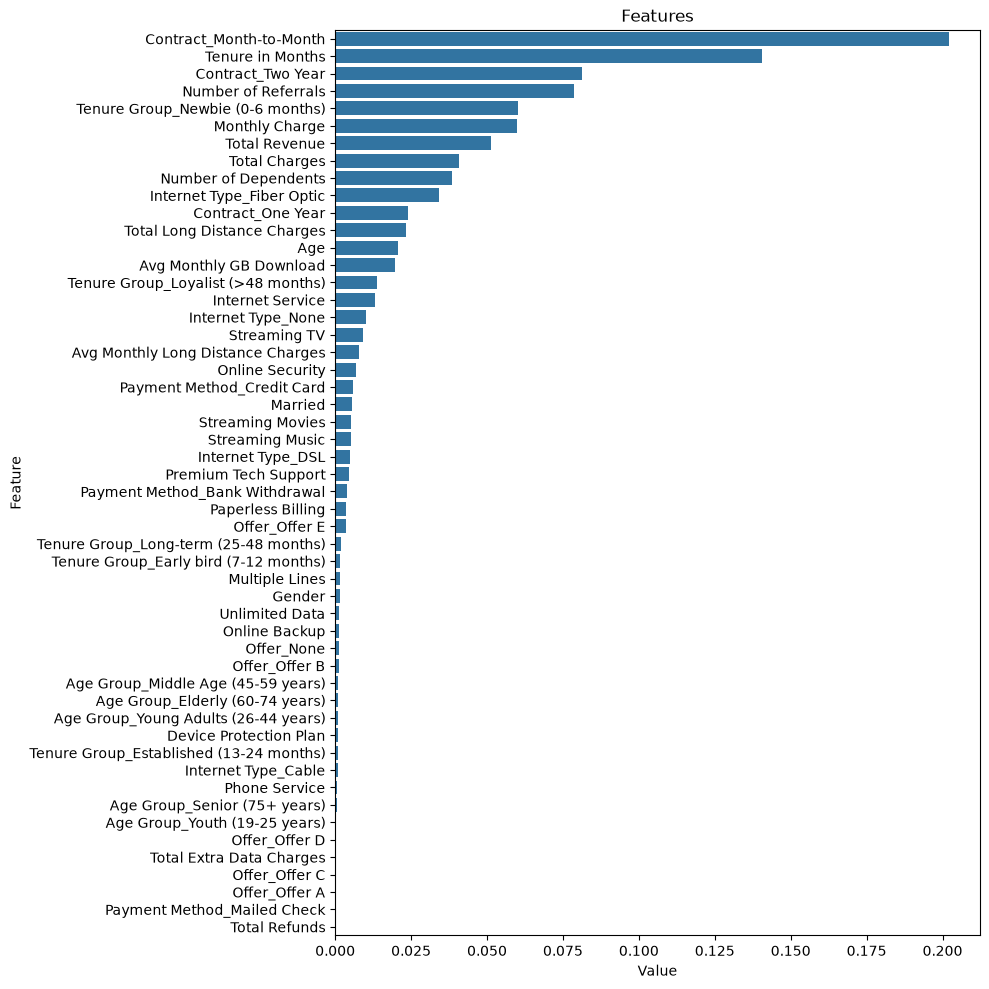

In [34]:
final_model = improved_metric_results[0]['final_model']
rf_model = final_model.named_steps['classifier']
feature_imp = pd.DataFrame({'Value': rf_model.feature_importances_
,
                            'Feature': final_model.named_steps['classifier'].feature_names_in_
})

plt.figure(figsize=(10, 10))
sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value",
                                                                    ascending=False))
plt.title('Features')
plt.tight_layout()
plt.savefig(f'images/feature_importance.png', bbox_inches='tight', dpi=300)
plt.show()

#### Overview

Overall, the model suggests a few important features that contributes most to predicting churn:

1. Month-to-month/ two year contract: 
2. Number of referrals: 
3. Tenure/ Newbie Tenure Group 0-6 months: 
4. Monthly Charge
5. Total Charges/ Total Revenue
6. Number of dependents
7. Fibre Optic Internet services
8. Age 

## 2. What do these features tell us about customer behavior?

It becomes necessary to compare churn rates across these features. 

In [35]:

#creating Monthly Charge Group
per_10, per_25, per_50, per_75, per_90 = df['Monthly Charge'].quantile([0.10, 0.25,0.5,0.75, 0.9])
def monthly_charges_mapping(monthly_charges):
    if monthly_charges <= per_10:
        return 'Low (0-' + str(per_10) + ')'
    elif monthly_charges <= per_25:
        return 'Low-Medium (' + str(per_10) + '-' + str(per_25) + ')'
    elif monthly_charges <= per_50:
        return 'Medium (' + str(per_25) + '-' + str(per_50) + ')'
    elif monthly_charges <= per_75:
        return 'Medium-High (' + str(per_50) + '-' + str(per_75) + ')'
    elif monthly_charges <= per_90:
        return 'High (' + str(per_75) + '-' + str(per_90) + ')'
    elif monthly_charges > per_90:
        return 'Very High (>' + str(per_90) + ')'

df['Monthly Charge Group'] = df['Monthly Charge'].apply(monthly_charges_mapping)


In [36]:
#creating Total Charges Group
per_10, per_25, per_50, per_75, per_90 = df['Total Charges'].quantile([0.10, 0.25,0.5,0.75, 0.9])
def total_charges_mapping(charges):
    if charges <= per_10:
        return 'Low (0-' + str(per_10) + ')'
    elif charges <= per_25:
        return 'Low-Medium (' + str(per_10) + '-' + str(per_25) + ')'
    elif charges <= per_50:
        return 'Medium (' + str(per_25) + '-' + str(per_50) + ')'
    elif charges <= per_75:
        return 'Medium-High (' + str(per_50) + '-' + str(per_75) + ')'
    elif charges <= per_90:
        return 'High (' + str(per_75) + '-' + str(per_90) + ')'
    elif charges > per_90:
        return 'Very High (>' + str(per_90) + ')'

df['Total Charges Group'] = df['Total Charges'].apply(total_charges_mapping)

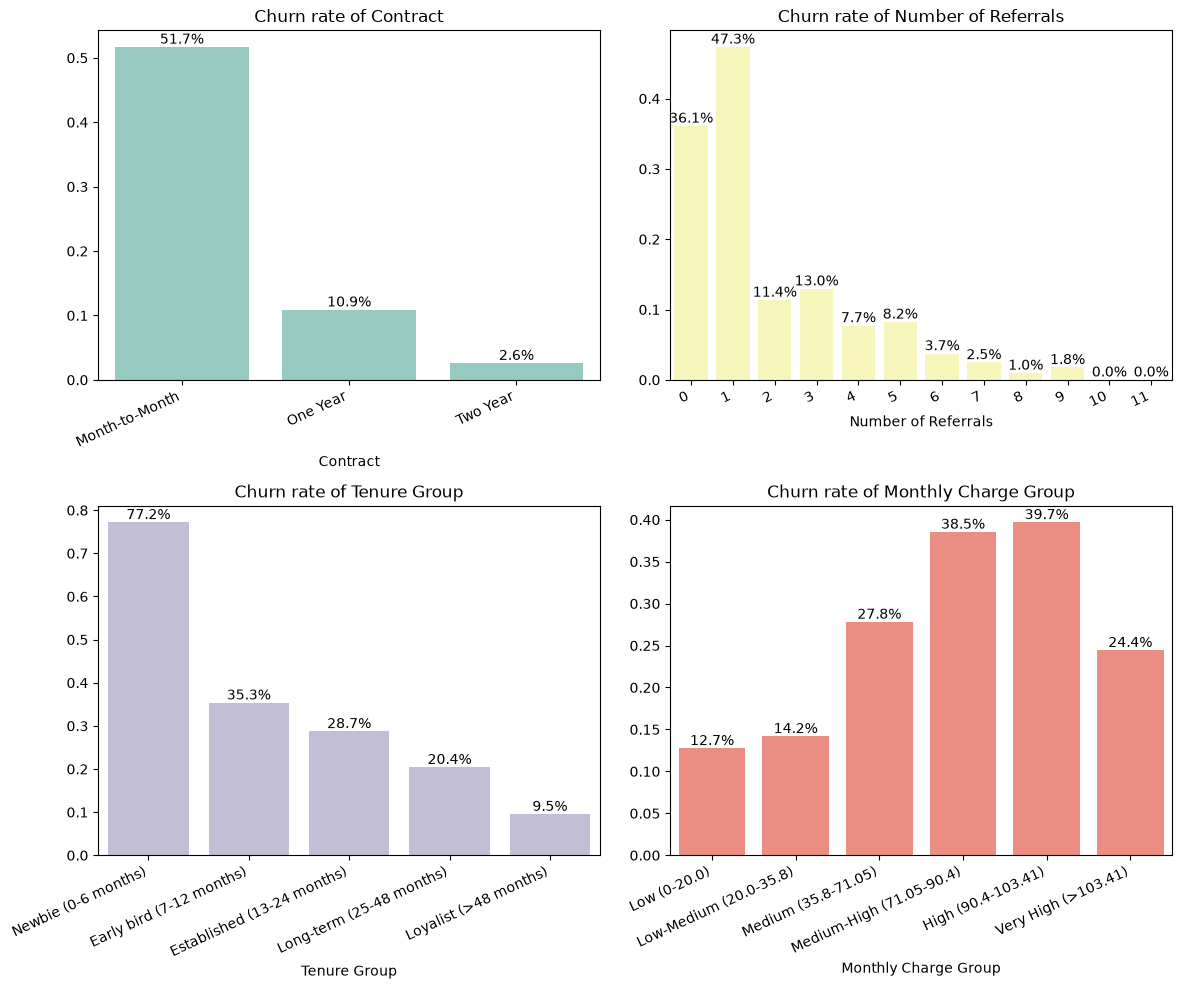

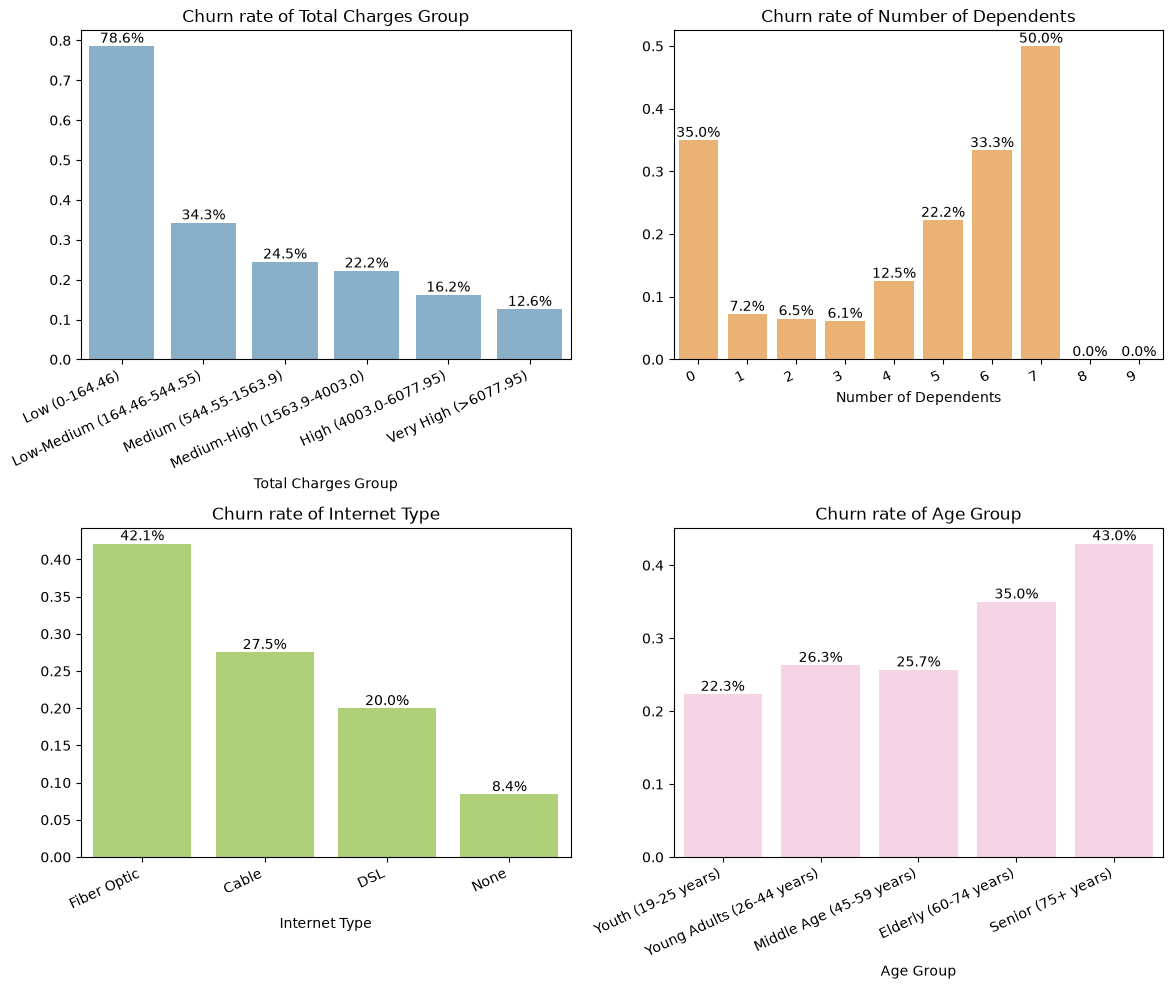

In [37]:
order_list = [ ['Month-to-Month', 'One Year', 'Two Year'],
              [0,1,2,3,4,5,6,7,8,9,10,11],
              ['Newbie (0-6 months)', 'Early bird (7-12 months)', 'Established (13-24 months)', 'Long-term (25-48 months)', 'Loyalist (>48 months)' ],
              ['Low (0-20.0)','Low-Medium (20.0-35.8)', 'Medium (35.8-71.05)', 'Medium-High (71.05-90.4)', 'High (90.4-103.41)','Very High (>103.41)'],
              ['Low (0-164.46)','Low-Medium (164.46-544.55)', 'Medium (544.55-1563.9)', 'Medium-High (1563.9-4003.0)', 'High (4003.0-6077.95)', 'Very High (>6077.95)'],
              [0,1,2,3,4,5,6,7,8,9],
              ['Fiber Optic', 'Cable', 'DSL', 'None'],          
              ['Youth (19-25 years)', 'Young Adults (26-44 years)', 'Middle Age (45-59 years)', 'Elderly (60-74 years)', 'Senior (75+ years)']              
            ]

impt_feature_list = ['Contract', 'Number of Referrals', 'Tenure Group', 'Monthly Charge Group', 'Total Charges Group', 'Number of Dependents', 'Internet Type', 'Age Group']

colors = sns.color_palette('Set3', len(impt_feature_list))
fig, axes = plt.subplots(2,2, figsize=(12,10))
i,j = 0,0
count = 0

for n in range(len(impt_feature_list)):
    df_plot = (
        df
        .groupby(impt_feature_list[n], as_index=False)['Churn Binary']
        .mean()
    )
    sns.barplot(
        data=df_plot,
        x=impt_feature_list[n],
        y='Churn Binary',
        order=order_list[n],
        color=colors[count],
        ax=axes[i,j]
    )   
    
    axes[i,j].set_title(f'Churn rate of {impt_feature_list[n]}')
    axes[i,j].set_ylabel('')
    axes[i,j].set_ylabel('')
    axes[i,j].tick_params(axis='x', labelrotation=25)
    plt.setp(axes[i,j].get_xticklabels(), ha='right')

    for container in axes[i,j].containers:
            label = [f'{v.get_height()*100:.1f}%' for v in container]
            axes[i,j].bar_label(container, labels=label )

    count+=1
    j+=1
    if j==2:
         i+=1
         j=0
    if i==2:
        plt.tight_layout()
        plt.savefig(f'images/churn_rate_key_features_{count//4}.png', bbox_inches='tight', dpi=300)
        plt.show()
        if count==len(impt_feature_list):
            break
        fig, axes = plt.subplots(2,2, figsize=(12,10))
        i,j = 0,0
if count % 8 != 0:
    plt.tight_layout()
    plt.show()


#### Overview

1. Month-to-month/ two year contract: 
    - As expected, lower contract terms provide more flexibility for the customer to cancel their subscription without incurring high cancellation fee. The team can explore various incentives for customers to upgrade to a longer-term contract.
2. Number of referrals: 
    - Customers who recommend are more likely to be satisfied and stay. Though high number of referrals may signal customer satisfaction, I do not think that the team should focus on incentives to increase referrals, but rather it should continue to find ways to keep customers satisfied.
3. Tenure/ Newbie Tenure Group 0-6 months: 
    - Churned customers have lower average tenure. This shows that early customer experience is key to retention. 
4. Monthly Charge
    - Churn rates increases as monthly charges increase, and are the highest around the range $71-$103~. This shows that customers are more likely to leave if competitors offer a better deal.
5. Total Charges/ Total Revenue
    - As expected, churned customers will have lower total charges compared to customers that stayed.
6. Number of dependents
    - U-shaped chart. Churn rate is high at 0 dependent, then drops at 1 dependent and climb as the number of dependents go up, which may suggest that as the household size increases, the number/ quality of services must increase as well. I.e. larger households have more devices that requires faster internet speed. This might be an opportunity for the company to explore competitive product mix among higher number of dependents.
7. Fiber Optic Internet services
    - Churn rates are the highest for customers with Fiber Optic compared to the other services. This signals the team to look into this particular offering and evaluate its attractiveness compared to competitors.
8. Age 
    - Churn rates are higher for older customers. 


## 3. Who are the at-risk customers who joined and stayed? What recommendations?

First, I will prepare a dataframe that contains both joined and stayed customers. This dataframe called `df_model_joined_stayed` will be fed into the model to generate churn risk of all existing customers.

In [38]:
# create age and tenure groupings
df_joined['Age Group'] = df_joined['Age'].apply(age_mapping)
df_joined['Tenure Group'] = df_joined['Tenure in Months'].apply(tenure_mapping)

df_model_joined = pd.DataFrame()

# one-hot-encodes categorical variables more than 2 unique values
df_model_joined = pd.get_dummies(df_joined[['Offer', 'Internet Type', 'Contract', 'Payment Method', 'Age Group', 'Tenure Group']], 
            columns=['Offer', 'Internet Type', 'Contract', 'Payment Method', 'Age Group', 'Tenure Group'], 
            dtype=int)

# binary encodes categorical varibles with 2 unique values
for col in modified_cat_cols_2:
    if len(df_joined[col].unique())==2:
        if 'Yes' in df[col].unique():
            df_model_joined[col] = (df_joined[col]=='Yes').astype(int)
        elif 'Male' in df[col].unique():
            df_model_joined[col] = (df_joined[col]=='Male').astype(int)

#adds in meaningul numerical columns
for col in modified_num_cols:
    df_model_joined[col] = df_joined[col]

#Joined customers are missing some one-hot-encoded columns. I.e. joined customers only have 'None' and 'Offer E', missing the remaining 4. This code adds in the remaining 4 missing columns as 0 vlaues. 
# for 
df_model_joined = df_model_joined.reindex(columns=final_model.feature_names_in_, fill_value=0)


In [39]:
df_model_stayed = df_model[df_model['Churn Binary']==0].drop('Churn Binary', axis=1)
df_model_joined_stayed = pd.concat([df_model_joined, df_model_stayed], axis=0)

#check if columns names match
print(set(df_model_stayed.columns) == set(df_model_joined.columns))

True


In [40]:
final_model = improved_metric_results[0]['final_model']

y_prob_joined_stayed = final_model.predict_proba(df_model_joined_stayed)[:,1]
y_pred_joined_stayed = final_model.predict(df_model_joined_stayed)

Next, I will merge the churn probabilities predicted by the model back in the a copy of the dataframe, `df_joined_stayed`. I will also create a Normalised Customer Value score from 0 to 1 that evaluates the value of each customer to the business.

Customer Value is evaluated by tenure, number of referrals, and monthly charges. Specifically, `0.45 tenure, 0.3 referral and 0.25 monthly charge`. 

In [41]:
#this cell is to reattach Customer ID and Customer Status and Churn Probability
df_joined_stayed = df_model_joined_stayed.copy()
df_joined_stayed[['Customer ID', 'Customer Status']] = telcom[['Customer ID', 'Customer Status']]
df_joined_stayed['Churn Prob'] = y_prob_joined_stayed


In [42]:
#These codes are to create a normalised Customer Value by averaging weights of Tenure, Referrals and Monthly Charge
df_joined_stayed['norm_tenure'] = (df_joined_stayed['Tenure in Months'] - df_joined_stayed['Tenure in Months'].min())/ (df_joined_stayed['Tenure in Months'].max() - df_joined_stayed['Tenure in Months'].min())
df_joined_stayed['norm_monthly_charge'] = (df_joined_stayed['Monthly Charge'] - df_joined_stayed['Monthly Charge'].min())/ (df_joined_stayed['Monthly Charge'].max() - df_joined_stayed['Monthly Charge'].min())
df_joined_stayed['norm_referral'] = (df_joined_stayed['Number of Referrals'] - df_joined_stayed['Number of Referrals'].min())/ (df_joined_stayed['Number of Referrals'].max() - df_joined_stayed['Number of Referrals'].min())
df_joined_stayed['Normalised Customer Value'] = 0.45*df_joined_stayed['norm_tenure'] + 0.3*df_joined_stayed['norm_referral'] + 0.25*df_joined_stayed['norm_monthly_charge']


Finally, once i have both the `Normalised Customer Value` and `Churn Prob`, i can categorise each customers into four quadrants and visualise them in a `Customer Value-Churn Risk Matrix`.

1. High value, high churn risk customers (`Protect and Retain`) 
2. High value, low churn risk customers (`Nurture Loyalty`)
3. Low value, high churn risk customers (`Targeted Retention`)
4. Low value, low churn risk customers (`Maintain Efficiently`)



In [43]:
def customer_risk_status(norm_cust_value, churn_prob):
    if norm_cust_value>=0.5 and churn_prob>=0.5:
        return 'Protect and Retain' 
    elif norm_cust_value>=0.5 and churn_prob<=0.5:
        return 'Nurture Loyalty'
    elif norm_cust_value<=0.5 and churn_prob>=0.5:
            return 'Targeted Retention'
    elif norm_cust_value<=0.5 and churn_prob<=0.5:
            return 'Maintain Efficiently'

df_joined_stayed['Value-Churn Status'] = df_joined_stayed.apply(lambda row:customer_risk_status(row['Normalised Customer Value'], row['Churn Prob']), axis=1)
df_prioritized_list = df_joined_stayed[['Customer ID', 'Customer Status', 'Normalised Customer Value', 'Churn Prob', 'Value-Churn Status']].sort_values(by=['Normalised Customer Value', 'Churn Prob'], ascending=[0,0])


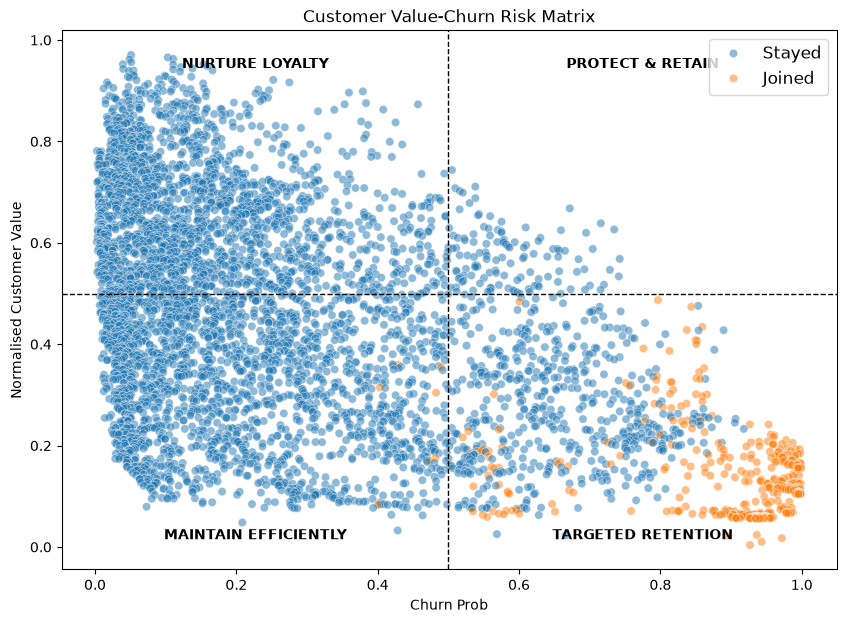

--------Count of customers in each quadrant--------
Value-Churn Status
Maintain Efficiently    2091
Nurture Loyalty         1961
Targeted Retention      1001
Protect and Retain       121
Name: count, dtype: int64


In [44]:
fig, axes = plt.subplots(figsize=(10, 7))

sns.scatterplot(data=df_prioritized_list, x='Churn Prob', y='Normalised Customer Value', hue='Customer Status', alpha=0.5)
plt.axvline(x=0.5, color='black', linestyle='--', linewidth=1)
plt.axhline(y=0.5, color='black', linestyle='--', linewidth=1)
plt.legend(fontsize=12, loc='upper right')
plt.title('Customer Value-Churn Risk Matrix')

# Quadrant labels
axes.text(0.25, 0.95, 'NURTURE LOYALTY',
        transform=axes.transAxes, ha='center', va='top', fontsize=10, weight='bold')
axes.text(0.75, 0.95, 'PROTECT & RETAIN',
        transform=axes.transAxes, ha='center', va='top', fontsize=10, weight='bold')
axes.text(0.25, 0.05, 'MAINTAIN EFFICIENTLY',
        transform=axes.transAxes, ha='center', va='bottom', fontsize=10, weight='bold')
axes.text(0.75, 0.05, 'TARGETED RETENTION',
        transform=axes.transAxes, ha='center', va='bottom', fontsize=10, weight='bold')
plt.savefig('images/customer_value_churn_risk_matrix.png', bbox_inches='tight',dpi=300)
plt.show()

print('--------Count of customers in each quadrant--------')
print(df_prioritized_list['Value-Churn Status'].value_counts())

#### Overview

`Protect and Retain` (High Risk, High Value) | <b>Highest Priority</b>
- These 121 customers have the been with the business the longest. They have a number of referrals and a monthly charge that is relatively high. However, they are also the ones that may be stuck with a weak service like Fiber Optic Internet on a month-to-month contract that makes it easy for them to swtich to another competitor. 

- <u>Recommendation</u>: The team should explore incentives to encourage them to swtich over to a longer term contract bundled with superior products. Additionally, the team should explore the issues associated with the Fiber Optic Internet service in terms of competitiveness, value and overall customer experience. Finally, the team may explore more attractive product mixes for households with more than 5 dependents, at a competitive value. For example, customers paying monthly charges in the range between $71 to $103 experience higher churn rates, and this could be due to lack of quality services, poor value and uncompetitive offerings overall.

`Targted Retention` (High Risk, Low Value) | <b>High Priority</b>
- These 1001 customers are newer and have lower tenure or referrals, but still have a high churn risk. Evidently, most of the newly joined customers are in this segment. However, as churned customers typically leave the business mostly within 6 months, it is imperative that the team contact these customers.

- <u>Recommendation</u>: The team should focus on methods that improve customer experience early on during the tenure by reducing friction during the first 6 months when customers are still evaluating whether the service meets their expectations. The team can experiment adding more proactive feedback measures and more responsive customer service to address any questions quickly. 

`Maintain Efficiently` (Low Risk, Low Value) | <b>Medium Priority</b>
- These 2091 customers form the majority of the segment. Although they have low churn risk, they also present an opportunity for the team to convert them into long term, high value customers.

- <u>Recommendation</u>: The team should continue to monitor changes in the customers' spending behavior overtime, which will be reflected in the normalised value score and churn risk as a key KPI. Using these as signals, the team should address any increases in churn risk or decreases in customer value timely.

`Nurture Loyalty` (Low Risk, High Value) | <b>Low Priority</b>
- These 1961 customers are the ideal customers. The business should strive to grow this segment.

- <u>Recommendation</u>: The team should continue to monitor these customers overtime and address increases in churn risk immediately.




---
# Final handoff

Saving the prioritised at-risk customers to handoff for the team.

In [45]:
df_prioritized_list.to_csv('output/prioritized_list.csv', index=False)

---
# Additional: AI-assisted coding to find best valid combination

My goal was to the find the best validation scores among all possible permutations of baseline, engineered features, downsampling, upsampling, important features, boruta and CV tuning. This is done with the help of chat GPT to generate, verify and clarify some codes. I would have an idea and write out a code, and used Chat GPT to verify if it works, and how it would generate a better code with more improvements. 

For example, I initally had the idea of looping through each valid combination, and using if-else statements to convert training set. A model that uses featured engineering, downsampling and boruta feature selection with CV would have its training set prepared first then fed into CV. However, I  verified my code with chat GPT and found that there is an issue of data leakage. Hence, I used GPT to generate codes for `important features` transformer and `boruta` transformers to be fed into the pipeline so that they are prepared within the CV loops.  I also asked GPT to improve `get_all_model_metrics_RSCV()` to include time stamps. 

In the process, I have learnt new codes, new concepts that will be beneficial to my skillsets. 

Overall, though I have learnt much from GPT, I will not attempt to code something like this again unless I properly understand what I am doing. 

## Part 1: Preparing pre-processing codes.

### a. Important features

The idea is to select only important features above threshold of 0.01 in variable selection.

In [46]:
#transformer
from sklearn.base import BaseEstimator, TransformerMixin

class ImportantFeaturesSelector(BaseEstimator, TransformerMixin):

    def __init__(self, threshold=0.01, random_state=42):
        self.threshold = threshold
        self.random_state = random_state

    def fit(self, X, y):

        # Train a random forest to calculate feature importance
        self.rf_model_ = RandomForestClassifier(
            random_state=self.random_state
        )

        self.rf_model_.fit(X, y)

        # Store feature importances
        feature_importances = pd.Series(
            self.rf_model_.feature_importances_,
            index=X.columns if isinstance(X, pd.DataFrame)
            else range(X.shape[1])
        )

        # Select features exceeding the threshold
        self.support_ = (
            feature_importances.values > self.threshold
        )

        # Keep the most important feature if none pass
        if not self.support_.any():
            self.support_[np.argmax(
                feature_importances.values
            )] = True

        return self

    def transform(self, X):

        # Retain only the selected features
        if isinstance(X, pd.DataFrame):
            return X.loc[:, self.support_]

        return np.asarray(X)[:, self.support_]


### b. Boruta variable selection

Boruta method is another variable selection technique.

In [47]:
#boruta transformer
from sklearn.base import BaseEstimator, TransformerMixin

class BorutaSelector(BaseEstimator, TransformerMixin):
    
    def __init__(self, random_state=42, max_iter=10):
        self.random_state = random_state
        self.max_iter = max_iter

    def fit(self, X, y):
        '''
        fit() is a method.        
        
        '''
        # self.feature_names_in_ checks whether X is a pandas DataFrame, and if it is, saves the column names. If not, it stores None.
        self.feature_names_in_ = (
            np.asarray(X.columns, dtype=object)
            if isinstance(X, pd.DataFrame)
            else None
        )

        boruta_model = RandomForestClassifier(
            random_state=self.random_state
        )
        # self.feat_selector_ creates Boruta selector
        self.feat_selector_ = BorutaPy(
            estimator=boruta_model,
            n_estimators='auto',
            max_iter=self.max_iter,
            random_state=self.random_state,
            verbose=0
        )
        # self.feat-selector_.fit() trains Boruta on data
        self.feat_selector_.fit(
            np.asarray(X),
            np.asarray(y)
        )

        # Bortua 's support_ is a Boolean mask for each input feature. self.support is an array of Boolean values.
        self.support_ = self.feat_selector_.support_


        # Use confirmed features first; if none are confirmed,
        # fall back to tentative features.
        # self.support_.any() checks whether at least one value is True.
        if not self.support_.any():
            self.support_ = self.feat_selector_.support_weak_

        if not self.support_.any():
            raise ValueError(
                "Boruta selected no features. "
                "Review the data or Boruta settings."
            )

        return self

    def transform(self, X):
        selected = np.asarray(X)[:, self.support_]

        if isinstance(X, pd.DataFrame):
            return pd.DataFrame(
                selected,
                columns=X.columns[self.support_],
                index=X.index
            )

        return selected



### c. Defining all valid strategies

Since downsampling > boruta may be different from boruta > downsampling, i decided to use permutation instead of combinations.

In [48]:
#define all valid strategies
def get_valid_strategies(strategies):
    valid_strategy_combos = []
    for r in range(1,len(strategies)+1):
        for permute in permutations(strategies, r):
            if 'downsampling' in permute and 'upsampling' in permute:
                continue
            if 'important features' in permute and 'boruta' in permute:
                continue
            if 'engineered features' in permute and permute[0]!= 'engineered features':
                continue
            valid_strategy_combos.append(permute)
    return valid_strategy_combos

strategies = ['engineered features', 'downsampling', 'upsampling', 'important features', 'boruta']
valid_strategy_combos = get_valid_strategies(strategies)

print(f'Number of valid combos: {len(valid_strategy_combos)}\n')
print(*valid_strategy_combos, sep='\n')

Number of valid combos: 25

('engineered features',)
('downsampling',)
('upsampling',)
('important features',)
('boruta',)
('engineered features', 'downsampling')
('engineered features', 'upsampling')
('engineered features', 'important features')
('engineered features', 'boruta')
('downsampling', 'important features')
('downsampling', 'boruta')
('upsampling', 'important features')
('upsampling', 'boruta')
('important features', 'downsampling')
('important features', 'upsampling')
('boruta', 'downsampling')
('boruta', 'upsampling')
('engineered features', 'downsampling', 'important features')
('engineered features', 'downsampling', 'boruta')
('engineered features', 'upsampling', 'important features')
('engineered features', 'upsampling', 'boruta')
('engineered features', 'important features', 'downsampling')
('engineered features', 'important features', 'upsampling')
('engineered features', 'boruta', 'downsampling')
('engineered features', 'boruta', 'upsampling')


### d. Building pipeline

In [49]:
#pipeline generator:
def build_pipeline(combo, random_state=42):
    steps = []

    for method in combo:

        if method == 'downsampling': steps.append(('sampler', RandomUnderSampler(random_state=random_state)))

        elif method == 'upsampling': steps.append(('sampler',RandomOverSampler(random_state=random_state)))

        elif method == 'important features':steps.append(('important_features', 
                                                          ImportantFeaturesSelector(threshold=0.01, random_state=random_state)))

        elif method == 'boruta':steps.append(('boruta', 
                                              BorutaSelector(random_state=random_state)))

    steps.append(('classifier', RandomForestClassifier(random_state=random_state)))

    return ImbPipeline(steps)

## Part 2: Comparing all possible valid strategy mix 

In [50]:
# WITH RandomisedSearchCV TUNING.

def get_all_model_metrics_RSCV(X_train, y_train):

    #start timer
    total_start = time.perf_counter()

    #include baseline metrics
    plot_results, metric_results = get_baseline_metrics(X_train, y_train)

     # Use consistent CV folds across strategies
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    #count valid strategies
    strategies = ['engineered features', 'downsampling', 'upsampling', 'important features', 'boruta']
    valid_strategy_combos = get_valid_strategies(strategies)
    total_valid_strategies = len(valid_strategy_combos)

    #initialise count 
    count = 0 

    for strategy in valid_strategy_combos:

        combo_start = time.perf_counter()
        model_name = ' + '.join(strategy)

        #retrieve fresh copy of training set each loop.
        X_train_current = X_train.copy()
        y_train_current = y_train.copy()

        #initialise status:
        status = 'SUCCESS'
        stage = 'initialisation'

        try:
            # 1. handling engineerd feature
            if 'engineered features' in strategy:
                stage = 'engineered features'
                X_train_current = do_eng_features(X_train_current)

            # 2. Building pipeline   
            stage = 'building pipeline'
            pipeline = build_pipeline(tuple(m for m in strategy if m != 'engineered features'))

            # 3. Running Cross Validation  
            stage = 'cross validation'
            rs_cv = RandomizedSearchCV(
                pipeline,  
                param_distributions= {f'classifier__{param}': values for param, values in rs_params.items()
},
                n_iter=5,
                cv=cv,
                scoring={
                    'recall': 'recall',
                    'precision': 'precision',
                    'f1': 'f1',
                    'roc_auc': 'roc_auc',
                    'average_precision': 'average_precision'
                },
                refit='f1',
                n_jobs=-1,
                verbose=0,
                random_state=42,
                error_score='raise',
                return_train_score=True
            )

            rs_cv.fit(X_train_current, y_train_current)

            # 4. Retrieving mean validation scores
            best_idx = rs_cv.best_index_
            search_results = rs_cv.cv_results_

            val_recall = round(
                search_results['mean_test_recall'][best_idx], 4
            )
            val_precision = round(
                search_results['mean_test_precision'][best_idx], 4
            )
            val_f1 = round(
                search_results['mean_test_f1'][best_idx], 4
            )
            val_roc_auc = round(
                search_results['mean_test_roc_auc'][best_idx], 4
            )
            val_pr_auc = round(
                search_results['mean_test_average_precision'][best_idx], 4
            )

            # 5. Fit the model on all training data
            best_params = rs_cv.best_params_
            final_model = rs_cv.best_estimator_

            # 6. Retrieving Out-of-fold predicted probabilities for the training data
            # also retrieve ROC and precision-recall curve points
            y_prob = cross_val_predict(final_model, X_train_current, y_train_current, cv=cv, method='predict_proba')[:, 1]
            y_pred = (y_prob >= 0.5).astype(int)
        
            fpr_rf, tpr_rf, _ = roc_curve(y_train_current, y_prob)
            precision_plot, recall_plot, _ = precision_recall_curve(y_train_current, y_prob)


            # 7. Store mean validation scores for ranking 
            metric_results.append({
                    'model_name' : model_name,
                    'recall' : val_recall,
                    'precision' : val_precision,
                    'f1' : val_f1,
                    'roc_auc': val_roc_auc,
                    'pr_auc': val_pr_auc,
                    'final_model': rf_model,
                    'best_params' : best_params
            })

            # 8. Store values for ROC curve and PR curve plot
            plot_results[model_name] = {
                'y_pred' : y_pred,
                'y_prob' : y_prob,
                'fpr': fpr_rf,
                'tpr': tpr_rf,
                'precision_plot': precision_plot,
                'recall_plot': recall_plot
            }
          
        
            status = 'SUCCESS'
        except Exception as e:
            status =  ((f'ERROR at {stage} ' 
                        f'[{type(e).__name__}: {e}]'))    

        # Calculate elapsed time for this combination
        combo_elapsed = time.perf_counter() - combo_start
        count +=1

        print(f'[{count:02d}/{total_valid_strategies}] {status} | {model_name}',
              f'{status} | {model_name} | 'f'Time: {combo_elapsed:.2f}s', flush=True)

    # Calculate total runtime, including baseline evaluation
    total_elapsed = time.perf_counter() - total_start

    minutes, seconds = divmod(total_elapsed, 60)
    hours, minutes = divmod(minutes, 60)

    print('-' * 75)
    print(
        f'Total runtime: {int(hours)}h '
        f'{int(minutes)}m {seconds:.2f}s'
    )
    print(f'Combinations processed: {total_valid_strategies}')

    return plot_results, metric_results
            

In [51]:
def print_metrics(plot_results, metric_results):   
    df_metric_results = pd.DataFrame(metric_results)
    top_5 = df_metric_results.sort_values(by=['recall', 'f1'], ascending=[False, False]).head(5)[['model_name', 'recall', 'f1']]
    bottom_5 = df_metric_results.sort_values(by=['recall', 'f1'], ascending=[True, True]).head(5)[['model_name', 'recall', 'f1']]
    print('--------------------Top 5 Models--------------------')
    print(top_5, end='\n\n\n')

    print('--------------------Bottom 5 Models--------------------')
    print(bottom_5, end='\n\n')

      
    # plot all ROC Curves of every model
    for model_name, results in plot_results.items():
        if model_name in top_5.head(3)['model_name'].values or model_name in bottom_5.head(3)['model_name'].values:
            plt.plot(results['fpr'], results['tpr'], label=model_name)
            continue
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.title(f'Top 3 vs bottom 3 comparison ROC Curve')
    plt.grid(True)
    plt.show()

    #plot all Precision-Recall Curves of every model
    for model_name, results in plot_results.items():  
        if model_name in top_5.head(3)['model_name'].values or model_name in bottom_5.head(3)['model_name'].values:
            plt.plot(results['recall_plot'], results['precision_plot'], label=model_name)  
            continue
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.legend(loc='lower right')
    plt.title(f'Top 3 vs bottom 3 comparison Precision-Recall')
    plt.grid(True)
    plt.show()

    #outputs model ranking in terms of recall and F1 score, plus maybe plot ROC and PR curve. 


In [52]:
seed = 42
X = df_baseline.drop('Churn Binary', axis=1)
y = df_baseline['Churn Binary']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state=seed, stratify=y)

all_plot_results, all_metric_results = get_all_model_metrics_RSCV(X_train, y_train)

[01/25] SUCCESS | engineered features SUCCESS | engineered features | Time: 36.22s
[02/25] SUCCESS | downsampling SUCCESS | downsampling | Time: 27.66s
[03/25] SUCCESS | upsampling SUCCESS | upsampling | Time: 35.57s
[04/25] SUCCESS | important features SUCCESS | important features | Time: 56.03s
[05/25] SUCCESS | boruta SUCCESS | boruta | Time: 157.35s
[06/25] SUCCESS | engineered features + downsampling SUCCESS | engineered features + downsampling | Time: 26.46s
[07/25] SUCCESS | engineered features + upsampling SUCCESS | engineered features + upsampling | Time: 46.66s
[08/25] SUCCESS | engineered features + important features SUCCESS | engineered features + important features | Time: 57.41s
[09/25] SUCCESS | engineered features + boruta SUCCESS | engineered features + boruta | Time: 150.07s
[10/25] SUCCESS | downsampling + important features SUCCESS | downsampling + important features | Time: 29.03s
[11/25] SUCCESS | downsampling + boruta SUCCESS | downsampling + boruta | Time: 84.5

--------------------Top 5 Models--------------------
                                                 model_name  recall      f1
18  engineered features + downsampling + important features  0.8388  0.7580
22  engineered features + important features + downsampling  0.8381  0.7593
11                                    downsampling + boruta  0.8361  0.7574
2                                              downsampling  0.8361  0.7529
10                        downsampling + important features  0.8348  0.7601


--------------------Bottom 5 Models--------------------
                                 model_name  recall      f1
9              engineered features + boruta  0.6642  0.7453
1                       engineered features  0.6716  0.7515
5                                    boruta  0.6769  0.7450
0                                  baseline  0.6876  0.7562
8  engineered features + important features  0.6890  0.7568



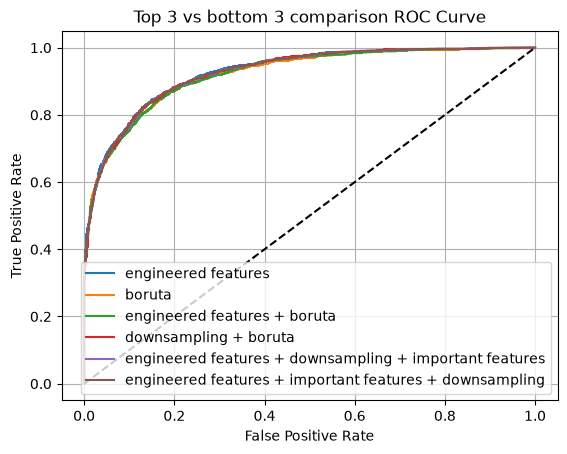

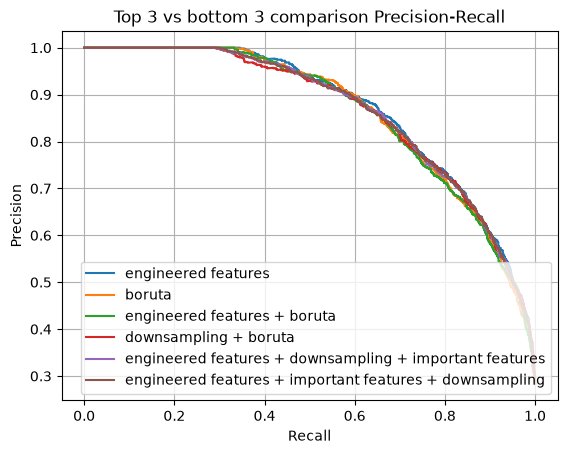

In [53]:
print_metrics(all_plot_results, all_metric_results)

#### Overview

Seems like the absolute best model is not much better than what we have. 